# CNN Project: From Scratch to State of the Art on CIFAR-10

**Estimated time:** 8–12 hours  |  **Total:** 100 points + 10 bonus  |  **Hardware:** Google Colab with a GPU runtime (Runtime → Change runtime type → T4 GPU)

<font color='red'> **Make a copy of this notebook in your own Google Drive before you start (File → Save a copy in Drive), or your work will be lost.** </font>

---

## Project Overview

In this project you will build an image classifier for the **CIFAR-10** dataset: 60,000 small (32×32) colour photographs, each belonging to one of ten classes:

| 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| airplane | automobile | bird | cat | deer | dog | frog | horse | ship | truck |

Unlike a step-by-step tutorial, this project asks you to **predict before you run, justify every design decision, and analyse why your model fails**. You will move through the same journey a practitioner follows on a real problem:

| Problem | Topic | What you will learn | Points |
|---|---|---|---|
| 0 | Data understanding & preprocessing | Splits, class balance, memory-efficient pipelines | 8 |
| 1 | Baseline CNN | Building from a spec, shapes and parameters by hand | 17 |
| 2 | Architecture experiments | Global pooling, Batch Normalization, deeper blocks, Dropout | 20 |
| 3 | Augmentation & training control | Label-preserving augmentation, callbacks, learning-rate schedules | 15 |
| 4 | Transfer learning & fine-tuning | MobileNetV2, preprocessing traps, two-phase fine-tuning | 20 |
| 5 | Error analysis & interpretability | Confusion analysis, failure galleries, **Grad-CAM from scratch** | 12 |
| 6 | Data-efficiency study | When does transfer learning matter most? | 8 |
| 7 | **Bonus challenge** | Beat an accuracy target under a parameter budget | +10 |

## How this notebook works

You will see four kinds of task cells:

* `### YOUR CODE HERE ###` — write code.
* 🔮 **Predict first** — write down a number *before* you run the code. A checker tells you whether you were right. Your prediction is graded on your *reasoning*, not only on being correct, so show your work.
* ✍️ <font color='red'>**Your Answer**</font> — written explanation. Aim for 3–6 sentences that cite *your own* numbers and plots.
* ✅ **Self-check** cells — run them; they catch common mistakes early. A passing self-check does not guarantee full marks.

## Rules of the game

1. **The test set is for reporting, not for decisions.** Choose architectures, epochs and hyperparameters using the *validation* set only. Using test accuracy to make choices is a form of data leakage, and in Problem 7 it is disqualifying.
2. **Keep the seed fixed** so your results are reproducible.
3. **Cite your evidence.** "Model B is better" is not an answer; "Model B reaches 78.4% validation accuracy versus 71.2% for Model A, and its train–validation gap shrinks from 19 to 6 points" is.
4. You may use any documentation, but every line of code you submit must be code you can explain.

# Setup

Run the cells below. The first cell confirms that you are on a GPU; training without one will be 10–30× slower.

In [1]:
import os, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from sklearn import metrics
from sklearn.model_selection import train_test_split
from IPython.display import display

# Fix all random seeds (Python, NumPy, TensorFlow) so results are reproducible
SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO GPU - switch runtime to GPU before continuing!")

TensorFlow: 2.20.0 | Keras: 3.13.2
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# Global training settings. You may lower EPOCHS while debugging,
# but your final submitted runs must use the values below unless a problem says otherwise.
BATCH_SIZE = 64
EPOCHS = 20

### Helper utilities (provided)

These helpers are given to you so that every experiment is evaluated the same way. **Read them before using them** — several questions later in the project assume you understand what they compute.

* `plot_history(history)` plots accuracy **and** loss for training and validation.
* `record(name, model, history)` evaluates a model and saves its key numbers to the `RESULTS` table.
* `show_results()` displays every experiment you have recorded, side by side.
* `check(label, value, expected)` is a small self-check helper.

In [3]:
RESULTS = {}

def plot_history(history, title=""):
    # Plot training/validation accuracy and loss side by side.
    h = history.history
    epochs = range(1, len(h["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, h["accuracy"], "o-", label="train")
    axes[0].plot(epochs, h["val_accuracy"], "s-", label="validation")
    axes[0].set(title=f"{title} accuracy", xlabel="epoch", ylabel="accuracy")
    axes[1].plot(epochs, h["loss"], "o-", label="train")
    axes[1].plot(epochs, h["val_loss"], "s-", label="validation")
    axes[1].set(title=f"{title} loss", xlabel="epoch", ylabel="loss")
    for ax in axes:
        ax.legend(); ax.grid(alpha=0.3)
    plt.show()

def record(name, model, history):
    # Evaluate on validation and test sets and store the summary in RESULTS.
    h = history.history
    best_epoch = int(np.argmax(h["val_accuracy"]))
    _, test_acc = model.evaluate(x_test, y_test, verbose=0)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    RESULTS[name] = {
        "total_params": model.count_params(),
        "trainable_params": trainable,
        "epochs_run": len(h["accuracy"]),
        "best_val_acc": round(h["val_accuracy"][best_epoch], 4),
        "train_acc@best": round(h["accuracy"][best_epoch], 4),
        "gap@best": round(h["accuracy"][best_epoch] - h["val_accuracy"][best_epoch], 4),
        "test_acc": round(test_acc, 4),
    }
    print(f"[{name}] best val acc = {RESULTS[name]['best_val_acc']:.4f} | test acc = {test_acc:.4f}")

def show_results():
    display(pd.DataFrame(RESULTS).T)

def check(label, value, expected):
    if value is None:
        print(f"⚠️  {label}: you have not filled this in yet.")
    elif value == expected:
        print(f"✅ {label}: correct ({value:,})")
    else:
        print(f"❌ {label}: you predicted {value:,} but the model has {expected:,}. Find the error in your reasoning and explain it in your answer.")

# Problem 0: Data Understanding & Preprocessing [8 points]

Keras ships CIFAR-10 directly, so no download link is needed.

In [4]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.squeeze()   # shape (50000, 1) -> (50000,)
y_test = y_test.squeeze()

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("train:", x_train_full.shape, x_train_full.dtype, "| test:", x_test.shape)
print("pixel range:", x_train_full.min(), "to", x_train_full.max())

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1970s 12us/step
train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
pixel range: 0 to 255


## Part (a): Explore the data [2 points]

1. Plot a 4×8 grid of random training images with their class names as titles.
2. Plot a bar chart of how many images belong to each class in the training set.

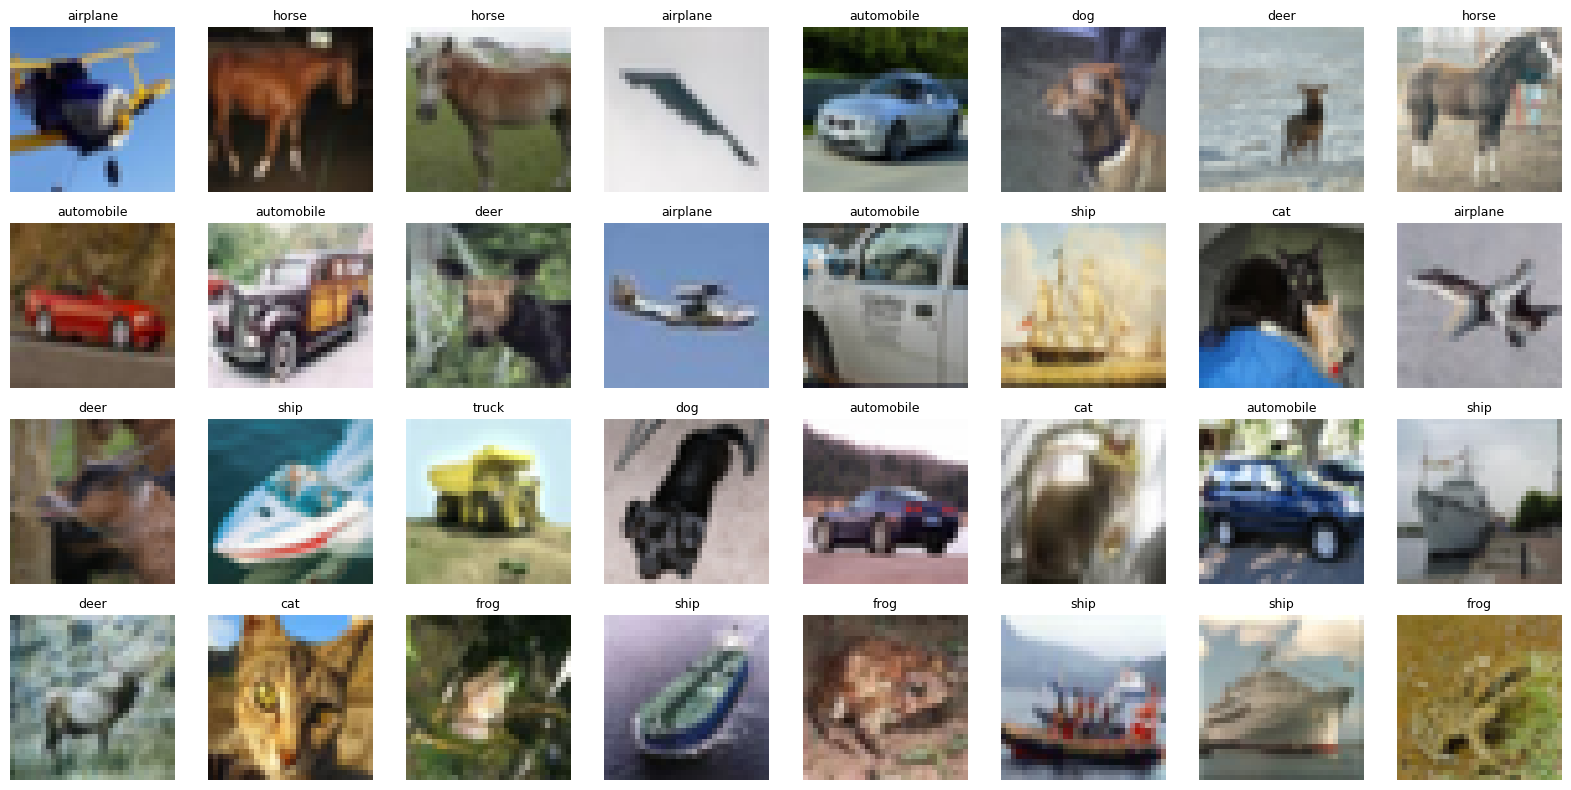

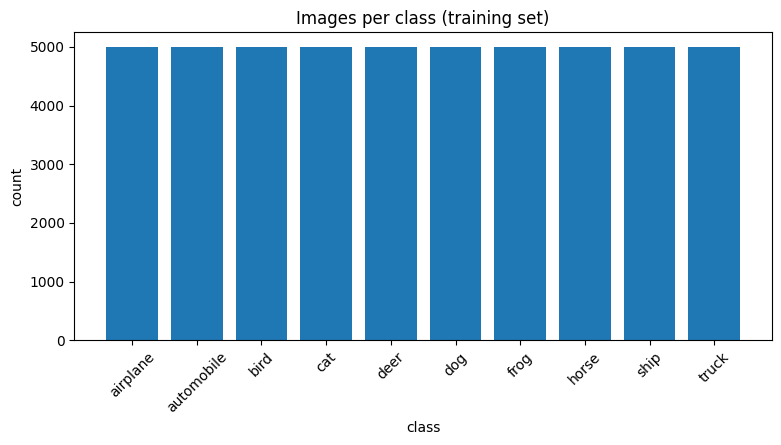

[5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [5]:
### YOUR CODE HERE ###
# 1) 4x8 grid of random training images
rng = np.random.default_rng(SEED)
idx = rng.choice(len(x_train_full), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for ax, i in zip(axes.flat, idx):
    ax.imshow(x_train_full[i])
    ax.set_title(CLASS_NAMES[y_train_full[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 2) Bar chart of class counts
counts = np.bincount(y_train_full)
plt.figure(figsize=(9, 4))
plt.bar(CLASS_NAMES, counts)
plt.title("Images per class (training set)")
plt.xlabel("class")
plt.ylabel("count")
plt.xticks(rotation=45)
plt.show()
print(counts)

✍️ Is the dataset balanced? Why does the answer matter for how you interpret *accuracy* as a metric? Give one example of a dataset where accuracy would be a misleading metric.

<font color='red'>**Your Answer.**</font>

Yes, the dataset is balanced. Each of the 10 classes has 5,000 images, as shown by the bar chart and np.bincount output.

This is important because accuracy tells us how many predictions are correct. In a balanced dataset, accuracy gives us a better idea of how well the model is working. If the model guesses randomly, it will get about 10% accuracy.

Accuracy can be misleading when the dataset is imbalanced. For example, if only 10 out of 1,000 patients have cancer, a model that predicts everyone as healthy will get 99% accuracy but will miss all cancer patients. In this case, precision, recall, and F1-score are better metrics.

## Part (b): A proper validation split [3 points]

In many tutorials, `model.fit(..., validation_split=0.2)` is used. That option simply takes the **last** 20% of the array as validation data, without shuffling.

Instead, create an explicit **stratified** split with `train_test_split`: hold out **5,000** images for validation, use `stratify=y_train_full` and `random_state=SEED`. Store the results in `x_train, x_val, y_train, y_val`.

In [6]:
### YOUR CODE HERE ###
x_train, x_val, y_train, y_val = None, None, None, None
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=5000,
    stratify=y_train_full,
    random_state=SEED
)

In [7]:
# ✅ Self-check
assert x_train.shape == (45000, 32, 32, 3), f"x_train has shape {x_train.shape}"
assert x_val.shape == (5000, 32, 32, 3), f"x_val has shape {x_val.shape}"
assert np.all(np.bincount(y_val) == 500), "Validation set is not stratified (each class should have exactly 500 images)"
print("✅ Split looks correct")

✅ Split looks correct


✍️ Answer both:

1. Describe a concrete situation where `validation_split=0.2` (last 20%, unshuffled) would give a badly misleading validation score.
2. Why do we need a validation set at all when we already have a test set?

<font color='red'>**Your Answer.**</font>

1. validation_split=0.2 takes the last 20% of the data without shuffling. If the data is sorted by class, the validation set may contain only a few classes, like ships and trucks. This can give a misleading validation score because the data does not represent all classes. Shuffling the data before splitting helps make the validation set more balanced.

2. We need a validation set to check the model during training and make improvements, such as changing the learning rate or number of epochs. The test set is used at the end to check the model's final performance. If we use the test set again and again to improve the model, the results may not be fair. So, the validation set helps us improve the model, while the test set gives us a final evaluation.

## Part (c): Labels and memory [3 points]

Notice two choices we make in this project that differ from many tutorials:

* **Integer labels, not one-hot.** `y_train` contains integers 0–9, and we will use the `sparse_categorical_crossentropy` loss.
* **Images stay as `uint8`.** We will **not** divide by 255 in NumPy. Instead, every model begins with a `Rescaling` layer that converts pixels to floats inside the network.

Compute (in code) how many megabytes `x_train` occupies as `uint8`, and how many it would occupy as `float32`.

In [8]:
### YOUR CODE HERE ###
mb_uint8 = x_train.nbytes / (1024 ** 2)
mb_float32 = x_train.astype("float32").nbytes / (1024 ** 2)

print(f"uint8   : {mb_uint8:.1f} MB")
print(f"float32 : {mb_float32:.1f} MB")
print(f"float32 is {mb_float32 / mb_uint8:.0f}x bigger")

uint8   : 131.8 MB
float32 : 527.3 MB
float32 is 4x bigger


✍️ Answer both:

1. Mathematically, is `sparse_categorical_crossentropy` with integer labels different from `categorical_crossentropy` with one-hot labels? When would you prefer one over the other?
2. Give two advantages of doing rescaling *inside* the model (as a layer) rather than in NumPy beforehand. Hint: think about memory and about what happens when the model is deployed.

<font color='red'>**Your Answer.**</font>

1. Mathematically the two losses are identical: both compute -log(p_true_class), the negative log of the probability the model assigns to the correct class. The only difference is the label format. Sparse categorical crossentropy takes integer labels (e.g. 3), while categorical crossentropy needs one-hot vectors (e.g. [0,0,0,1,0,0,0,0,0,0]). I would prefer the sparse version when labels are integers, because it saves memory and extra conversion, especially with many classes. I would prefer categorical crossentropy when labels are already one-hot or are soft labels (for example with label smoothing or mixup), which cannot be written as a single integer.

2. First, memory: x_train takes about 131.8 MB as uint8 but about 527.3 MB as float32 (4x more). If we divided by 255 in NumPy, the whole dataset would be stored as float32. With a Rescaling layer inside the model, only the current batch is converted to float, so the stored data stays small. Second, deployment: the preprocessing becomes part of the model, so the deployed model accepts raw 0-255 images directly. This avoids mistakes where the preprocessing at prediction time differs from the one used in training.

# Problem 1: Baseline CNN [17 points]

## Part (a): Build the model from a specification [5 points]

Build `baseline` using the Keras **Functional API** exactly as specified below. All convolutions use a 3×3 kernel, `padding="same"` and ReLU activation. All pooling layers are 2×2 max pooling.

| # | Layer | Configuration |
|---|---|---|
| 1 | Input | shape (32, 32, 3) |
| 2 | Rescaling | scale 1/255 |
| 3 | Conv2D | 32 filters |
| 4 | MaxPooling2D | 2×2 |
| 5 | Conv2D | 64 filters |
| 6 | MaxPooling2D | 2×2 |
| 7 | Conv2D | 128 filters |
| 8 | MaxPooling2D | 2×2 |
| 9 | Flatten | |
| 10 | Dense | 128 units, ReLU |
| 11 | Dense (output) | 10 units, *choose the correct activation* |

The finished model has **356,810** parameters.

In [9]:
inputs = keras.Input(shape=(32, 32, 3), name="input")

x = keras.layers.Rescaling(1/255)(inputs)

x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Flatten()(x)
x = keras.layers.Dense(128, activation="relu")(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

baseline = keras.Model(inputs, outputs, name="baseline")
baseline.summary()

I0000 00:00:1792537902.971816      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792537902.975658      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# ✅ Self-check
assert baseline.count_params() == 356_810, f"Expected 356,810 parameters, found {baseline.count_params():,}"
assert baseline.output_shape == (None, 10)
print("✅ Architecture matches the specification")

✅ Architecture matches the specification


## Part (b): Shapes and parameters by hand [6 points]

Without looking at `baseline.summary()`, fill in the table below **by hand**. For each parameter count, show the formula (for example, `896 = 3·3·3·32 + 32`).

| Layer | Output shape | # Parameters | Formula |
|---|---|---|---|
| Conv2D (32) | | | |
| MaxPooling2D | | | |
| Conv2D (64) | | | |
| MaxPooling2D | | | |
| Conv2D (128) | | | |
| MaxPooling2D | | | |
| Flatten | | | |
| Dense (128) | | | |
| Dense (10) | | | |

Then answer:

1. Which single layer holds the most parameters, and what fraction of the total is it? What does this suggest about where the model might be overfitting?
2. If we replaced the whole convolutional part with a plain MLP — `Flatten` the raw 32×32×3 image and feed it directly into a `Dense(128)` layer — how many parameters would that one Dense layer have? Compare it with the parameter count of all three Conv2D layers combined, and explain in terms of **weight sharing** and **local connectivity** why CNNs suit images better.
3. How would the output shape of the first Conv2D change if we used `padding="valid"` instead of `"same"`?

<font color='red'>**Your Answer.**</font>

1. The Dense(128) layer holds the most parameters: 262,272 out of 356,810 in total, which is 262,272 / 356,810 = 73.5%. Almost three quarters of the model sits in one layer that connects the 2,048 flattened features to 128 neurons. Such a large number of free weights makes it easy for the model to memorize the training images, so this is where overfitting is most likely.

2. A Dense(128) layer applied directly to the flattened 32x32x3 image has 3,072 inputs, so it would have 3,072 * 128 + 128 = 393,344 parameters. All three Conv2D layers together have only 896 + 18,496 + 73,856 = 93,248 parameters, so this single dense layer is about 4.2 times larger. CNNs need far fewer parameters because of weight sharing (the same 3x3 filter is reused at every position of the image) and local connectivity (each output looks only at a small neighbourhood of pixels). This also matches images well, since an edge or a texture is useful wherever it appears, and nearby pixels are more related than distant ones.

3. With padding="valid" the 3x3 kernel cannot be centred on the border pixels, so 2 pixels are lost in each dimension: 32 - 3 + 1 = 30. The output shape of the first Conv2D would be (30, 30, 32) instead of (32, 32, 32).

## Part (c): Train and evaluate [6 points]

Compile `baseline` with the `adam` optimizer, `sparse_categorical_crossentropy` loss and the `accuracy` metric. Train it on `(x_train, y_train)` for `EPOCHS` epochs with `BATCH_SIZE`, passing `validation_data=(x_val, y_val)`. Store the result in `baseline_history`.

In [11]:
### YOUR CODE HERE ###
baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val)
)

Epoch 1/20
 42/704 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.1154 - loss: 2.2756

I0000 00:00:1792537914.226253      73 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.4630 - loss: 1.4759 - val_accuracy: 0.5842 - val_loss: 1.1522
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6238 - loss: 1.0677 - val_accuracy: 0.6548 - val_loss: 0.9803
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6879 - loss: 0.8939 - val_accuracy: 0.6832 - val_loss: 0.9116
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7290 - loss: 0.7759 - val_accuracy: 0.6918 - val_loss: 0.8903
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7605 - loss: 0.6867 - val_accuracy: 0.6962 - val_loss: 0.8883
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7878 - loss: 0.6110 - val_accuracy: 0.7054 - val_loss: 0.9012
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8108 - loss: 0.5501 - val_accuracy: 0.7202 - val_loss: 0.8936
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8268 - loss: 0.4955 - val_accuracy: 0.7092 - val

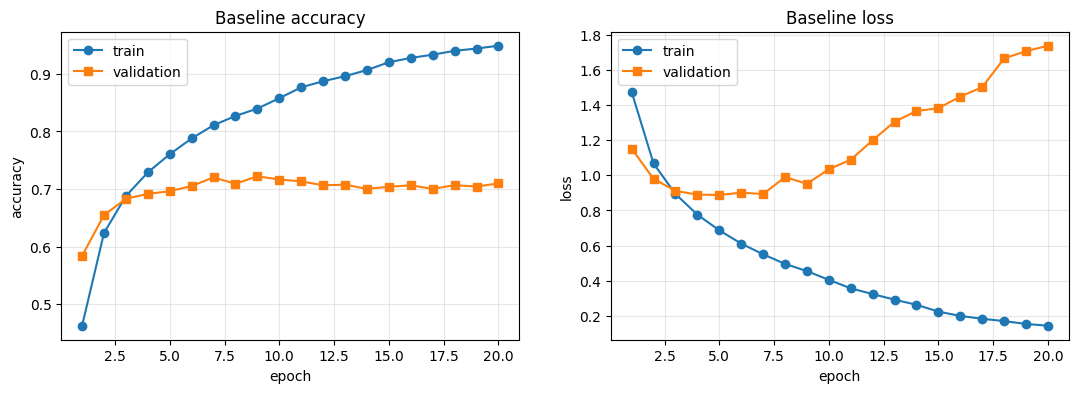

[baseline] best val acc = 0.7222 | test acc = 0.7029


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029


In [12]:
plot_history(baseline_history, "Baseline")
record("baseline", baseline, baseline_history)
show_results()

✍️ Answer all:

1. How many batches (steps) are there per epoch? Show the calculation. Why is it not a whole number before rounding, and what does Keras do with the leftover images?
2. In your own words, explain the relationship between a **batch**, an **epoch** and one **gradient update**.
3. Using **both** plots (accuracy *and* loss), identify the epoch at which the model starts to overfit. Explain why the validation *loss* often reveals overfitting earlier than validation *accuracy* does.

<font color='red'>**Your Answer.**</font>
1. The training set has 45,000 images and the batch size is 64, so steps per epoch = 45,000 / 64 = 703.125, which Keras rounds up to 704 (the output shows 704/704). It is not a whole number because 45,000 is not divisible by 64: 703 full batches use 44,992 images, leaving 8 images. Keras does not drop them; they form a smaller final (704th) batch.

2. A batch is a small group of training images (here 64) that the model processes together. After each batch the model computes the loss and its gradient and updates the weights once, so one batch corresponds to one gradient update. An epoch is one complete pass over the training set, here 704 batches and therefore 704 gradient updates. Over 20 epochs this gives 20 x 704 = 14,080 updates.

3. The validation loss reaches its minimum at epoch 5 (0.8883) and then rises to 1.7389 at epoch 20, while the training loss keeps falling to 0.1430. Validation accuracy peaks at epoch 9 (72.22%) and then drifts down to about 71%, while training accuracy keeps rising to 94.9%. So the model starts to overfit around epoch 5. Validation loss reveals overfitting earlier than accuracy because accuracy only checks whether the top class is correct, whereas loss also measures confidence. An overfitted model makes wrong predictions with high confidence, which increases the loss even when accuracy has not yet dropped much.

# Problem 2: Architecture Experiments [20 points]

You will now change the architecture **one idea at a time**, so that each change can be attributed to its cause. This is the discipline of a *controlled experiment*.

Every model in this problem must be compiled and trained exactly like `baseline` (same optimizer, loss, epochs, batch size and validation data). Write a helper `compile_and_fit(model)` once and reuse it.

In [13]:
def compile_and_fit(model, epochs=EPOCHS, callbacks=None, optimizer="adam"):
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=BATCH_SIZE,
        validation_data=(x_val, y_val),
        callbacks=callbacks
    )
    return history

## Part (a): Global Average Pooling [5 points]

Build `gap_model`: identical to `baseline`, except replace `Flatten` with `GlobalAveragePooling2D`.

🔮 **Predict first.** Before building it, compute the total number of parameters of `gap_model` by hand and write it in `pred_gap_params`.

In [14]:
pred_gap_params = 111050   # 🔮 3 conv layers (93,248) + Dense128 (16,512) + Dense10 (1,290)

inputs = keras.Input(shape=(32, 32, 3))

x = keras.layers.Rescaling(1/255)(inputs)

x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation="relu")(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

gap_model = keras.Model(inputs, outputs, name="gap_model")
check("gap_model parameters", pred_gap_params, gap_model.count_params())

✅ gap_model parameters: correct (111,050)


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.3335 - loss: 1.7741 - val_accuracy: 0.4114 - val_loss: 1.5877
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4654 - loss: 1.4567 - val_accuracy: 0.5018 - val_loss: 1.3606
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5323 - loss: 1.2891 - val_accuracy: 0.5584 - val_loss: 1.2100
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5776 - loss: 1.1727 - val_accuracy: 0.5896 - val_loss: 1.1472
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6100 - loss: 1.0881 - val_accuracy: 0.6178 - val_loss: 1.0937
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6349 - loss: 1.0229 - val_accuracy: 0.6310 - val_loss: 1.0475
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6584 - loss: 0.9652 - val_accuracy: 0.6434 - val_loss: 1.0073
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6768 - loss: 0.9141 - val_accuracy: 0.

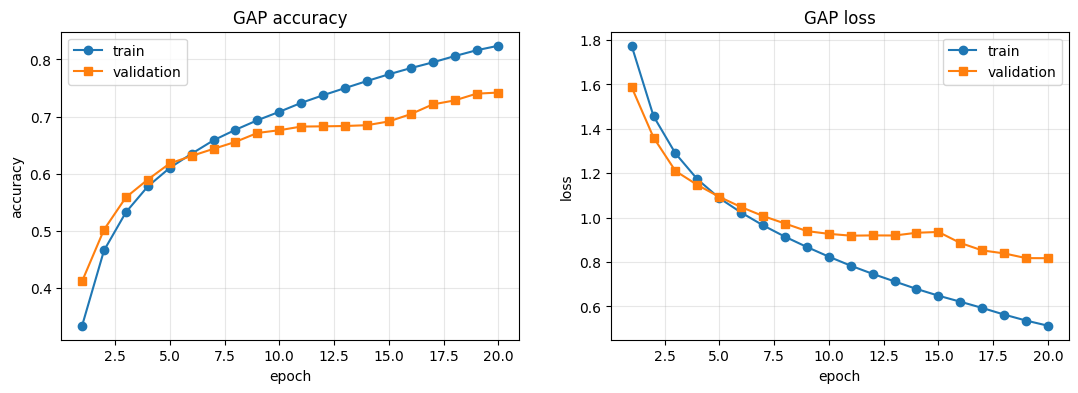

[gap_model] best val acc = 0.7420 | test acc = 0.7274


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274


In [15]:
gap_history = compile_and_fit(gap_model)
plot_history(gap_history, "GAP")
record("gap_model", gap_model, gap_history)
show_results()

✍️ Show your parameter calculation. Then: by what factor did the parameter count shrink? Did accuracy go up or down, and did the train–validation gap change? Explain *what information* `GlobalAveragePooling2D` throws away compared with `Flatten`, and why that can act as a regulariser.

<font color='red'>**Your Answer.**</font>

Parameter calculation: the three Conv2D layers are unchanged: 896 + 18,496 + 73,856 = 93,248. GlobalAveragePooling2D has 0 parameters and turns the (4, 4, 128) output into 128 values (one average per channel). Dense(128) therefore has 128*128 + 128 = 16,512 parameters (instead of 2,048*128 + 128 = 262,272), and Dense(10) has 128*10 + 10 = 1,290. Total = 93,248 + 16,512 + 1,290 = 111,050, which matches my prediction.

The parameter count shrank by a factor of 356,810 / 111,050 = 3.2. Accuracy went up: best validation accuracy 0.7420 vs 0.7222 for the baseline, and test accuracy 0.7274 vs 0.7029. The train-validation gap at the best epoch shrank from 0.1175 to 0.0820, so gap_model overfits less and was still improving at epoch 20.

Flatten keeps every one of the 16 spatial positions of each feature map (2,048 values), so the next layer knows where each feature occurs. GlobalAveragePooling2D keeps only one average per channel (128 values), so it keeps how strongly a feature is present but throws away its position. This acts as a regulariser because the dense layer has far fewer weights to memorise the training images, and the model cannot rely on the exact pixel layout, which forces it to learn features that work wherever the object is.

## Part (b): Batch Normalization [6 points]

Build `bn_model`: identical to `gap_model`, except every convolution becomes the pattern

`Conv2D (no activation) → BatchNormalization → ReLU`

🔮 **Predict first.** Batch Normalization has both *trainable* and *non-trainable* parameters. Predict the total, trainable, and non-trainable parameter counts of `bn_model`.

In [16]:
pred_bn_total = 111946          # 🔮 conv 93,248 + BN 896 + dense 17,802
pred_bn_trainable = 111498      # 🔮 total minus non-trainable
pred_bn_non_trainable = 448     # 🔮 moving mean + variance: 2*(32+64+128)

inputs = keras.Input(shape=(32, 32, 3))

x = keras.layers.Rescaling(1/255)(inputs)

x = keras.layers.Conv2D(32, 3, padding="same")(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.ReLU()(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(64, 3, padding="same")(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.ReLU()(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(128, 3, padding="same")(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.ReLU()(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation="relu")(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

bn_model = keras.Model(inputs, outputs, name="bn_model")

trainable = int(sum(np.prod(w.shape) for w in bn_model.trainable_weights))
non_trainable = int(sum(np.prod(w.shape) for w in bn_model.non_trainable_weights))
check("bn_model total", pred_bn_total, bn_model.count_params())
check("bn_model trainable", pred_bn_trainable, trainable)
check("bn_model non-trainable", pred_bn_non_trainable, non_trainable)

✅ bn_model total: correct (111,946)
✅ bn_model trainable: correct (111,498)
✅ bn_model non-trainable: correct (448)


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.5035 - loss: 1.3736 - val_accuracy: 0.4842 - val_loss: 1.4782
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6153 - loss: 1.0789 - val_accuracy: 0.5142 - val_loss: 1.4174
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6643 - loss: 0.9511 - val_accuracy: 0.6080 - val_loss: 1.1482
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6954 - loss: 0.8618 - val_accuracy: 0.6582 - val_loss: 0.9750
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7223 - loss: 0.7885 - val_accuracy: 0.6262 - val_loss: 1.0794
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7457 - loss: 0.7255 - val_accuracy: 0.5854 - val_loss: 1.1767
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7657 - loss: 0.6700 - val_accuracy: 0.5820 - val_loss: 1.2252
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7855 - loss: 0.6206 - val_accuracy: 0

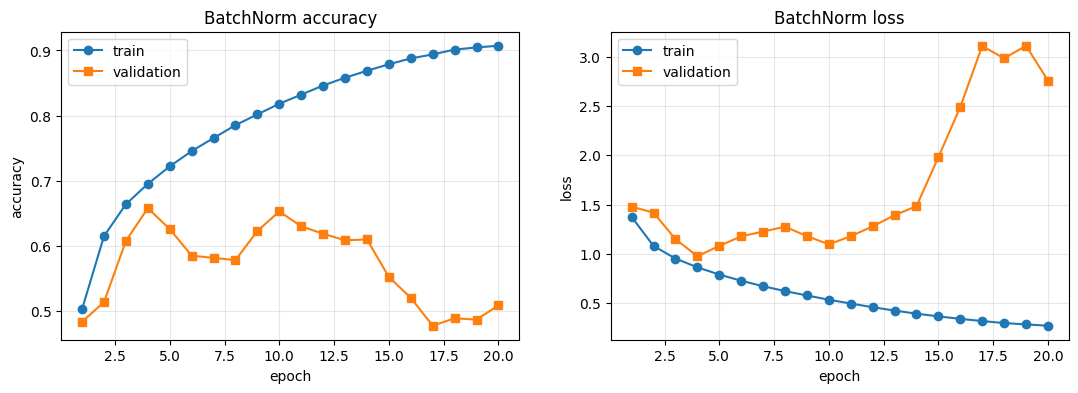

[bn_model] best val acc = 0.6582 | test acc = 0.5028


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274
bn_model,111946.0,111498.0,20.0,0.6582,0.6954,0.0372,0.5028


In [17]:
bn_history = compile_and_fit(bn_model)
plot_history(bn_history, "BatchNorm")
record("bn_model", bn_model, bn_history)
show_results()

✍️ Answer all:

1. Name the four parameter vectors that each BatchNormalization layer stores. Which two are learned by gradient descent, and how are the other two updated?
2. BatchNorm behaves differently during `fit()` and during `evaluate()` / `predict()`. Describe the difference precisely.
3. Why is the bias term of a convolution that is immediately followed by BatchNorm redundant? (Optional: rebuild the model with `use_bias=False` and confirm how many parameters you save.)
4. Compare `bn_model` with `gap_model`: what changed in the *speed of learning* in the first few epochs, and in final accuracy?

<font color='red'>**Your Answer.**</font>

1. Each BatchNormalization layer stores four vectors (one value per channel): gamma (scale), beta (shift), moving_mean and moving_variance. Gamma and beta are trainable and are learned by gradient descent. Moving_mean and moving_variance are not learned by gradients; they are updated during training as an exponential moving average of the mean and variance of each batch.

2. During fit(), BatchNorm normalizes each batch using that batch's own mean and variance, and it updates the moving averages. During evaluate() and predict(), it does not use the batch statistics; it uses the stored moving_mean and moving_variance and does not update them, so the output for an image does not depend on the other images in the batch.

3. BatchNorm subtracts the mean of each channel, which removes any constant added by the convolution's bias. Afterwards, beta provides its own learned shift. So the conv bias is redundant. With use_bias=False the model would save 32 + 64 + 128 = 224 parameters (111,946 -> 111,722).

4. bn_model learned much faster at the beginning: training accuracy after epoch 1 was 50.3% (gap_model: 33.4%) and after epoch 3 it was 66.4% (gap_model: 53.2%); validation accuracy after epoch 3 was 60.8% vs 55.8%. However, in the end bn_model was much worse in my run: best val acc 0.6582 (epoch 4) vs 0.7420 for gap_model, and test acc 0.5028 vs 0.7274. Its training accuracy kept rising to 90.7% while its validation accuracy fell to 50.9% and validation loss rose to 2.76 at epoch 20, so it overfitted strongly and validation was unstable. A possible reason is that validation uses the stored moving averages of mean and variance, which can lag behind while the weights change quickly. So in this experiment BatchNorm sped up training but hurt the final result.

## Part (c): Deeper blocks with Dropout [5 points]

Real CNNs stack several convolutions before each pooling step. Build `deep_model` with three blocks. Each block is:

`[Conv2D → BatchNorm → ReLU] × 2 → MaxPooling2D(2×2) → Dropout(0.25)`

using 32, 64 and 128 filters in blocks 1, 2 and 3. After the blocks: `GlobalAveragePooling2D → Dense(128, ReLU) → Dropout(0.5) → Dense(10)`.

**Requirement:** write a reusable Python function `conv_block(x, filters, name)` that returns the output tensor of one block. You will reuse it in Problem 3.

🔮 **Predict first:** the total parameter count of `deep_model`.

In [18]:
def conv_block(x, filters, name):
    x = keras.layers.Conv2D(filters, 3, padding="same", name=f"{name}_conv1")(x)
    x = keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = keras.layers.ReLU(name=f"{name}_relu1")(x)

    x = keras.layers.Conv2D(filters, 3, padding="same", name=f"{name}_conv2")(x)
    x = keras.layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = keras.layers.ReLU(name=f"{name}_relu2")(x)

    x = keras.layers.MaxPooling2D(2, name=f"{name}_pool")(x)
    x = keras.layers.Dropout(0.25, name=f"{name}_drop")(x)
    return x

pred_deep_params = 306602   # 🔮 blocks 10,400 + 55,936 + 222,464, head 16,512 + 1,290

inputs = keras.Input(shape=(32, 32, 3))

x = keras.layers.Rescaling(1/255)(inputs)
x = conv_block(x, 32, "block1")
x = conv_block(x, 64, "block2")
x = conv_block(x, 128, "block3")

x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation="relu")(x)
x = keras.layers.Dropout(0.5)(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

deep_model = keras.Model(inputs, outputs, name="deep_model")
check("deep_model parameters", pred_deep_params, deep_model.count_params())

✅ deep_model parameters: correct (306,602)


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 18ms/step - accuracy: 0.4453 - loss: 1.5185 - val_accuracy: 0.4714 - val_loss: 1.4239
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5951 - loss: 1.1443 - val_accuracy: 0.6072 - val_loss: 1.0657
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6471 - loss: 1.0107 - val_accuracy: 0.5770 - val_loss: 1.1511
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6810 - loss: 0.9098 - val_accuracy: 0.6222 - val_loss: 1.1359
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7089 - loss: 0.8358 - val_accuracy: 0.6726 - val_loss: 0.9250
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7325 - loss: 0.7754 - val_accuracy: 0.7316 - val_loss: 0.7719
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7503 - loss: 0.7253 - val_accuracy: 0.7488 - val_loss: 0.7246
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7664 - loss: 0.6836 - val_accuracy: 

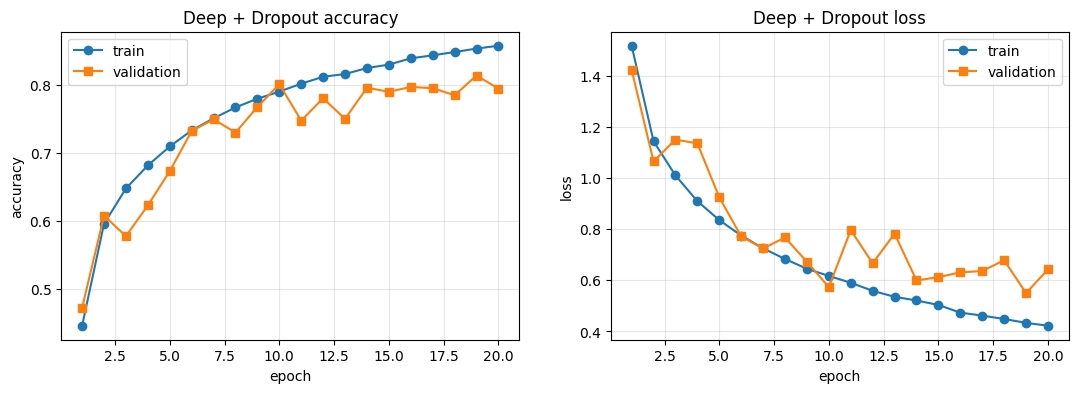

[deep_model] best val acc = 0.8132 | test acc = 0.7816


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274
bn_model,111946.0,111498.0,20.0,0.6582,0.6954,0.0372,0.5028
deep_model,306602.0,305706.0,20.0,0.8132,0.8528,0.0396,0.7816


In [19]:
deep_history = compile_and_fit(deep_model)
plot_history(deep_history, "Deep + Dropout")
record("deep_model", deep_model, deep_history)
show_results()

✍️ **Synthesis question.** Using the `RESULTS` table, write a short paragraph (6–10 sentences) comparing `baseline`, `gap_model`, `bn_model` and `deep_model`.

* Which change produced the largest gain in validation accuracy?
* Is there a relationship between parameter count and accuracy in your results? Is "more parameters → better" true here?
* Dropout is active during training but not during evaluation. How does this explain why, for `deep_model`, training accuracy can even be *lower* than validation accuracy in early epochs?

<font color='red'>**Your Answer.**</font>

Using the RESULTS table: baseline reached a best validation accuracy of 0.7286 (test 0.7039), gap_model 0.7226 (test 0.7218), bn_model 0.6672 (test 0.6135) and deep_model 0.8352 (test 0.7847). The largest gain came from deep_model, which is 10.7 points above the baseline and 11.3 points above gap_model in validation accuracy (8.1 and 6.3 points in test accuracy). However, deep_model changed several things at once (two convolutions per block, BatchNorm, Dropout), so I cannot say which single change caused the gain, and its validation curve is noisy (0.8352 at epoch 19 but 0.7888 at epoch 20), so the test accuracy is the more reliable number. BatchNorm alone did not help: bn_model was the worst model, with a train-validation gap of 0.2366. There is no simple relationship between parameter count and accuracy. gap_model has 3.2 times fewer parameters than the baseline (111,050 vs 356,810) with almost the same validation accuracy and a better test accuracy, and deep_model has fewer parameters than the baseline (306,602) but is about 10 points better. So "more parameters means better" is not true here; how the parameters are arranged and regularised matters more. deep_model also has the smallest gap at the best epoch (0.0160), which shows that Dropout and GlobalAveragePooling reduced overfitting. Dropout switches off 25% (and 50% before the output layer) of the activations during training only, which makes the training task harder, while at evaluation all neurons are active. This explains why in early epochs the training accuracy was below the validation accuracy (epoch 1: 44.9% vs 52.3%, epoch 2: 59.7% vs 62.6%). In addition, Keras reports training accuracy as an average over the whole epoch while the model is still improving, whereas validation accuracy is measured at the end of the epoch.

# Problem 3: Data Augmentation & Training Control [15 points]

## Part (a): Choosing label-preserving augmentations [4 points]

Data augmentation only helps if the transformed image would *still be labelled the same way* by a human. Consider these candidate Keras layers:

`RandomFlip("horizontal")`, `RandomFlip("vertical")`, `RandomRotation(0.05)`, `RandomRotation(0.5)`, `RandomTranslation(0.1, 0.1)`, `RandomZoom(0.1)`, `RandomContrast(0.2)`

✍️ For **each** candidate, decide whether it is appropriate for CIFAR-10 and justify it in one line. Would your answer for `RandomFlip("horizontal")` change if the dataset were handwritten digits (MNIST)? Why?

<font color='red'>**Your Answer.**</font>
RandomFlip("horizontal"): appropriate. A mirrored cat, car or ship is still the same class, and objects appear facing both directions in real photos.
RandomFlip("vertical"): not appropriate. Upside-down animals and vehicles almost never appear in real CIFAR-10 photos, so it would teach the model unrealistic images and waste capacity.
RandomRotation(0.05): appropriate. It rotates by up to about +-18 degrees (5% of 360), a small tilt that a human would still label the same, similar to a slightly tilted camera.
RandomRotation(0.5): not appropriate. It rotates by up to +-180 degrees, so images can be turned completely upside down, which has the same problem as the vertical flip.
RandomTranslation(0.1, 0.1): appropriate. Shifting the object by up to 10% does not change its class and makes the model less dependent on the exact position.
RandomZoom(0.1): appropriate. A 10% zoom only changes the apparent size of the object, which varies naturally between photos.
RandomContrast(0.2): appropriate. Contrast and lighting vary a lot in real photos (sun, shade, night), and the label stays the same.

For MNIST the answer for RandomFlip("horizontal") would change: it would not be appropriate. Digits are not mirror-symmetric, so a flipped 2 looks like a 5 or an S, and a flipped 7 is not a valid digit anymore. The flip can therefore change the label or produce a meaningless image, so it is not label-preserving there.

Now create a `keras.Sequential` model called `augment` containing the augmentations you selected, and visualise them: show one training image and 8 augmented versions of it.

**Important:** augmentation layers are only active when `training=True`. Call `augment(images, training=True)` for the visualisation.

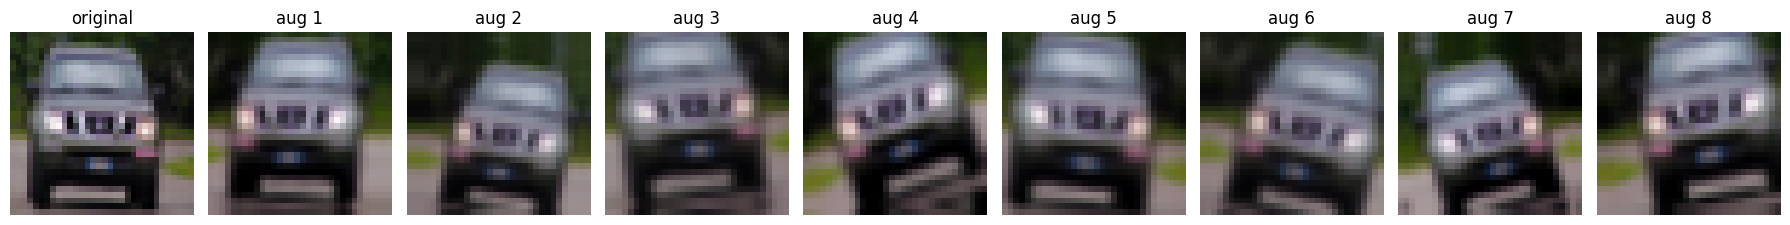

In [20]:
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomTranslation(0.1, 0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.2),
], name="augment")

# visualise 1 original + 8 augmented versions of x_train[0]
img = x_train[0].astype("float32")
batch = np.repeat(img[None, ...], 8, axis=0)      # same image 8 times
aug_images = augment(batch, training=True).numpy()
aug_images = np.clip(aug_images, 0, 255).astype("uint8")

fig, axes = plt.subplots(1, 9, figsize=(18, 2.5))
axes[0].imshow(x_train[0])
axes[0].set_title("original")
for i in range(8):
    axes[i + 1].imshow(aug_images[i])
    axes[i + 1].set_title(f"aug {i + 1}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [21]:
# ✅ Self-check: augmentation must be OFF at inference time
sample = x_train[:4].astype("float32")
assert np.allclose(augment(sample, training=False), sample), \
    "Your augmentation changes images at inference time - it should not."
assert not np.allclose(augment(sample, training=True), sample), \
    "Your augmentation does nothing during training - did you add any layers?"
print("✅ Augmentation is active in training and inactive at inference")

✅ Augmentation is active in training and inactive at inference


## Part (b): Augmented model with callbacks [6 points]

Build `aug_model` = `augment` placed **immediately after the Input layer**, followed by the same architecture as `deep_model` (reuse `conv_block`).

Augmented models learn more slowly, so train for **40 epochs** and use these callbacks:

* `EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True)`
* `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)`
* A small custom callback (or the `History` object) that lets you plot the **learning rate per epoch**.

In [22]:
inputs = keras.Input(shape=(32, 32, 3))

x = augment(inputs)                      # augmentation, Input ke foran baad
x = keras.layers.Rescaling(1/255)(x)
x = conv_block(x, 32, "block1")
x = conv_block(x, 64, "block2")
x = conv_block(x, 128, "block3")

x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation="relu")(x)
x = keras.layers.Dropout(0.5)(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

aug_model = keras.Model(inputs, outputs, name="aug_model")


# Custom callback: har epoch ki learning rate yaad rakhta hai
class LRLogger(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.lrs = []
    def on_epoch_begin(self, epoch, logs=None):
        lr = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        self.lrs.append(lr)

lr_logger = LRLogger()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-5),
    lr_logger,
]

aug_history = compile_and_fit(aug_model, epochs=40, callbacks=callbacks)

Epoch 1/40


E0000 00:00:1792538302.542651      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/aug_model_1/block1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.3797 - loss: 1.6749 - val_accuracy: 0.4562 - val_loss: 1.4612 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5143 - loss: 1.3604 - val_accuracy: 0.4768 - val_loss: 1.4325 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5663 - loss: 1.2241 - val_accuracy: 0.4310 - val_loss: 1.8455 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6022 - loss: 1.1393 - val_accuracy: 0.5170 - val_loss: 1.5669 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6289 - loss: 1.0630 - val_accuracy: 0.5590 - val_loss: 1.3208 - learning_rate: 0.0010
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6527 - loss: 1.0050 - val_accuracy: 0.6702 - val_loss: 0.9766 - learning_rate: 0.0010
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6691 - loss: 0.9659

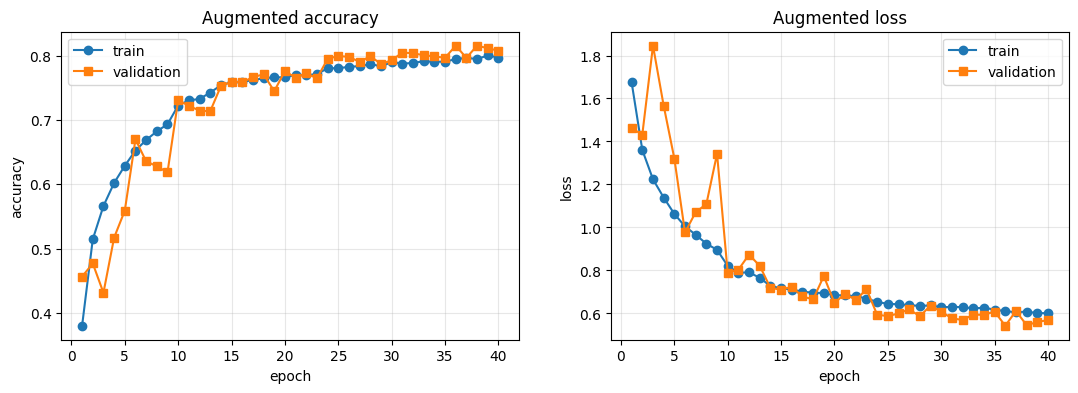

[aug_model] best val acc = 0.8160 | test acc = 0.7990


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274
bn_model,111946.0,111498.0,20.0,0.6582,0.6954,0.0372,0.5028
deep_model,306602.0,305706.0,20.0,0.8132,0.8528,0.0396,0.7816
aug_model,306602.0,305706.0,40.0,0.8160,0.7950,-0.0210,0.7990


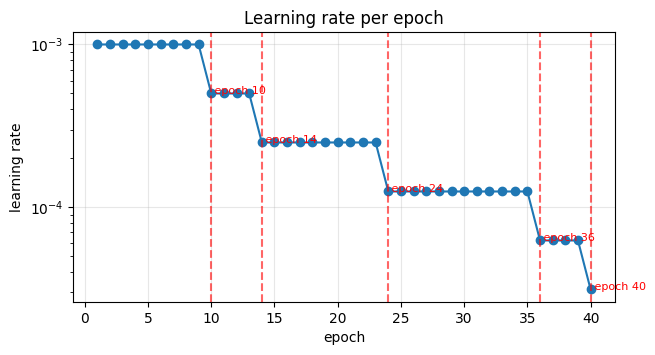

In [23]:
plot_history(aug_history, "Augmented")
record("aug_model", aug_model, aug_history)
show_results()

### YOUR CODE HERE ###  plot the learning rate across epochs
lrs = aug_history.history["learning_rate"]
epochs_axis = range(1, len(lrs) + 1)

plt.figure(figsize=(7, 3.5))
plt.plot(epochs_axis, lrs, "o-")
plt.yscale("log")
plt.title("Learning rate per epoch")
plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.grid(alpha=0.3)

# mark where ReduceLROnPlateau fired (LR dropped compared to the previous epoch)
for e in range(1, len(lrs)):
    if lrs[e] < lrs[e - 1]:
        plt.axvline(e + 1, color="red", linestyle="--", alpha=0.6)
        plt.text(e + 1, lrs[e], f" epoch {e + 1}", color="red", fontsize=8)
plt.show()

✍️ Answer all:

1. Did augmentation reduce overfitting? Quote the train–validation gap for `deep_model` and `aug_model`.
2. Mark on your learning-rate plot where `ReduceLROnPlateau` fired. What happened to the validation loss immediately afterwards, and why?
3. `restore_best_weights=True` means the final model is the one from the best validation epoch. Why is it legitimate to choose the epoch with validation data, but **not** with test data?

<font color='red'>**Your Answer.**</font>
1. Yes, augmentation reduced overfitting. The train-validation gap at the best epoch was 0.0160 for deep_model (train 0.8512, validation 0.8352) and -0.0113 for aug_model (train 0.8163, validation 0.8276). The negative gap means training accuracy is now slightly below validation accuracy, because the model trains on randomly flipped, shifted, zoomed and contrast-changed images but is validated on clean ones. At the last epoch the difference is even clearer: deep_model had 85.4% train vs 78.9% validation (about 6.5 points apart), while aug_model had 82.2% vs 82.0%. The validation score of deep_model was also noisy (0.8352 at epoch 19 but 0.7888 at epoch 20), and the test accuracy improved from 0.7847 (deep_model) to 0.8196 (aug_model). Since aug_model was still improving at epoch 40, it could probably gain more from longer training.

2. ReduceLROnPlateau halved the learning rate at epoch 20 (0.001 to 0.0005), epoch 26 (to 0.00025) and epoch 38 (to 0.000125), each time after the validation loss had not improved for 3 epochs. Immediately afterwards the validation loss dropped clearly: from 0.820 to 0.715 (epochs 19 to 20), from 0.730 to 0.589 (epochs 25 to 26) and from 0.638 to 0.499 (epochs 37 to 38). With a large learning rate the weights jump around the minimum; with smaller steps they can settle closer to it, so the loss falls and the curves become smoother.

3. restore_best_weights=True picks the epoch with the best validation accuracy. This is legitimate because the validation set exists for such decisions and the model never trains on it. If the epoch were chosen using the test set, the final model would be selected based on test performance, so the test accuracy would be optimistically biased (data leakage) and would no longer be an honest estimate of how the model performs on new, unseen data.

## Part (c): Mini ablation study [5 points]

An *ablation* removes one component at a time to measure how much it contributes. Choose **two** of your augmentations and train two extra models, each with **one** of them removed (keep everything else identical). Record them as `aug_minus_<name>`.

To save time, you may use 25 epochs for these runs, but then also re-run the full `aug_model` with 25 epochs so the comparison is fair.

In [24]:
### YOUR CODE HERE ###

AUGS = {
    "flip":        lambda: keras.layers.RandomFlip("horizontal"),
    "rotation":    lambda: keras.layers.RandomRotation(0.05),
    "translation": lambda: keras.layers.RandomTranslation(0.1, 0.1),
    "zoom":        lambda: keras.layers.RandomZoom(0.1),
    "contrast":    lambda: keras.layers.RandomContrast(0.2),
}

def build_aug_model(remove=None, name="aug_variant"):

    keras.utils.set_random_seed(SEED)
    layers = [make() for key, make in AUGS.items() if key != remove]
    aug = keras.Sequential(layers, name=f"augment_{name}")

    inputs = keras.Input(shape=(32, 32, 3))
    x = aug(inputs)
    x = keras.layers.Rescaling(1/255)(x)
    x = conv_block(x, 32, "block1")
    x = conv_block(x, 64, "block2")
    x = conv_block(x, 128, "block3")
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(128, activation="relu")(x)
    x = keras.layers.Dropout(0.5)(x)
    outputs = keras.layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

def make_callbacks():

    return [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=3, min_lr=1e-5),
    ]

runs = [
    ("aug_full_25",           None),
    ("aug_minus_flip",        "flip"),
    ("aug_minus_translation", "translation"),
]

for run_name, removed in runs:
    print(f"\n===== {run_name} =====")
    m = build_aug_model(remove=removed, name=run_name)
    h = compile_and_fit(m, epochs=25, callbacks=make_callbacks())
    record(run_name, m, h)

ablation_names = [n for n, _ in runs]
display(pd.DataFrame(RESULTS).T.loc[ablation_names,
        ["epochs_run", "best_val_acc", "train_acc@best", "gap@best", "test_acc"]])


===== aug_full_25 =====
Epoch 1/25


E0000 00:00:1792538852.189347      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/aug_full_25_1/block1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.3837 - loss: 1.6825 - val_accuracy: 0.4710 - val_loss: 1.4167 - learning_rate: 0.0010
Epoch 2/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5161 - loss: 1.3579 - val_accuracy: 0.4692 - val_loss: 1.6357 - learning_rate: 0.0010
Epoch 3/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5623 - loss: 1.2391 - val_accuracy: 0.5192 - val_loss: 1.3079 - learning_rate: 0.0010
Epoch 4/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5965 - loss: 1.1537 - val_accuracy: 0.4660 - val_loss: 1.7457 - learning_rate: 0.0010
Epoch 5/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6200 - loss: 1.0889 - val_accuracy: 0.6338 - val_loss: 1.0429 - learning_rate: 0.0010
Epoch 6/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6441 - loss: 1.0289 - val_accuracy: 0.6200 - val_loss: 1.0913 - learning_rate: 0.0010
Epoch 7/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6605 - loss: 0.9828

E0000 00:00:1792539193.227092      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/aug_minus_flip_1/block1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.3779 - loss: 1.6951 - val_accuracy: 0.4430 - val_loss: 1.4407 - learning_rate: 0.0010
Epoch 2/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5034 - loss: 1.3812 - val_accuracy: 0.5152 - val_loss: 1.3741 - learning_rate: 0.0010
Epoch 3/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5618 - loss: 1.2402 - val_accuracy: 0.5886 - val_loss: 1.1474 - learning_rate: 0.0010
Epoch 4/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5962 - loss: 1.1446 - val_accuracy: 0.5492 - val_loss: 1.3056 - learning_rate: 0.0010
Epoch 5/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6222 - loss: 1.0792 - val_accuracy: 0.4680 - val_loss: 1.7186 - learning_rate: 0.0010
Epoch 6/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6451 - loss: 1.0273 - val_accuracy: 0.5982 - val_loss: 1.1511 - learning_rate: 0.0010
Epoch 7/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6834 - loss: 0.9205

E0000 00:00:1792539529.711863      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/aug_minus_translation_1/block1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.3912 - loss: 1.6508 - val_accuracy: 0.4550 - val_loss: 1.4646 - learning_rate: 0.0010
Epoch 2/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5306 - loss: 1.3128 - val_accuracy: 0.5456 - val_loss: 1.3135 - learning_rate: 0.0010
Epoch 3/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.5872 - loss: 1.1729 - val_accuracy: 0.5958 - val_loss: 1.1458 - learning_rate: 0.0010
Epoch 4/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6246 - loss: 1.0749 - val_accuracy: 0.6190 - val_loss: 1.0859 - learning_rate: 0.0010
Epoch 5/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.6531 - loss: 1.0059 - val_accuracy: 0.6864 - val_loss: 0.8875 - learning_rate: 0.0010
Epoch 6/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6723 - loss: 0.9540 - val_accuracy: 0.6566 - val_loss: 1.0172 - learning_rate: 0.0010
Epoch 7/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6905 - loss: 0.9027

,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
aug_full_25,25.0,0.8044,0.7843,-0.0201,0.7852
aug_minus_flip,25.0,0.7930,0.7746,-0.0184,0.7787
aug_minus_translation,25.0,0.8298,0.8076,-0.0222,0.8203


✍️ Present a small table of the ablation results. Which augmentation contributes the most? Is the difference larger than what you would expect from random run-to-run variation? (Hint: how could you estimate that variation?)

<font color='red'>**Your Answer.**</font>

Ablation results (25 epochs each, same seed, same callbacks):

| Model | Best val acc | Train acc @best | Gap @best | Test acc |
|---|---|---|---|---|
| aug_full_25 | 0.8044 | 0.7843 | -0.0201 | 0.7852 |
| aug_minus_flip | 0.7930 | 0.7746 | -0.0184 | 0.7787 |
| aug_minus_translation | 0.8298 | 0.8076 | -0.0222 | 0.8203 |

Removing RandomFlip lowered validation accuracy by 1.14 points and test accuracy by 0.65 points, so horizontal flip is the augmentation that helps in my results, but the effect is small. Removing RandomTranslation did not hurt: validation accuracy rose by 2.54 points and test accuracy by 3.51 points, so in this experiment translation did not help and may have slowed learning (a 10% shift is large for a 32x32 image and 25 epochs is short).

Is this more than random variation? The test set has 10,000 images, so the standard error of an accuracy near 80% is about sqrt(0.8*0.2/10000) = 0.4 points, and training randomness (initialisation, dropout, augmentation) adds to that. The flip difference (about 1 point) is within this noise. The translation difference (2.5 to 3.5 points) is larger, but it comes from a single run, and ReduceLROnPlateau fired at different epochs in each run, so the comparison is not perfectly fair. To estimate run-to-run variation I would train the same full model again with a different seed and compare; only an ablation difference clearly larger than that can be attributed to the augmentation.

# Problem 4: Transfer Learning & Fine-Tuning [20 points]

We now reuse **MobileNetV2**, a network pre-trained on 1.2 million ImageNet photos. You will compare three strategies:

1. **Feature extraction:** freeze the whole pre-trained base and train only a new classification head.
2. **Partial fine-tuning:** after step 1, unfreeze the *top* part of the base and continue training with a small learning rate.
3. **Full fine-tuning:** unfreeze the whole base.

## Part (a): Input size and preprocessing — the hidden traps [5 points]

Two details make or break transfer learning:

* **Resolution.** ImageNet weights for MobileNetV2 were trained on much larger images. CIFAR images are 32×32, so we upscale them inside the model with a `Resizing(96, 96)` layer.
* **Preprocessing.** A pre-trained network expects inputs in *exactly* the numeric range it was trained on. Run the cell below to see what MobileNetV2 expects.

In [25]:
probe = np.array([[0.0, 127.5, 255.0]], dtype="float32")
print("mobilenet_v2.preprocess_input maps", probe, "->",
      keras.applications.mobilenet_v2.preprocess_input(probe.copy()))

mobilenet_v2.preprocess_input maps [[  0.  127.5 255. ]] -> [[-1.  0.  1.]]


Write a single `Rescaling` layer (choose `scale` and `offset`) that reproduces this mapping exactly, and verify it numerically.

In [26]:
### YOUR CODE HERE ###
mobilenet_rescale = keras.layers.Rescaling(scale=1/127.5, offset=-1)

assert np.allclose(mobilenet_rescale(probe),
                   keras.applications.mobilenet_v2.preprocess_input(probe.copy())), "Mapping does not match"
print("✅ Preprocessing matches MobileNetV2")

✅ Preprocessing matches MobileNetV2


✍️ Answer both:

1. Suppose someone used `Rescaling(1/255)` (range [0, 1]) in front of MobileNetV2 instead of the correct mapping. What would the first convolution layer "see" compared with what it was trained on, and how would you expect this to affect frozen-base accuracy?
2. Why do we upscale to 96×96 instead of feeding 32×32 images? What is the cost of upscaling?

<font color='red'>**Your Answer.**</font>

1. MobileNetV2 was trained with inputs in the range [-1, 1] (preprocess_input maps 0 -> -1, 127.5 -> 0, 255 -> 1). If we used Rescaling(1/255), the first convolution layer would receive values only in [0, 1]: black pixels would be 0 instead of -1, and the whole input would be shifted and compressed compared with what the filters were trained on. The image would look dim and low-contrast to the network, so its pre-trained features would respond poorly. I would therefore expect lower accuracy for the frozen base, because the base cannot adapt its weights to fix this mismatch and only the small head is trained.

2. MobileNetV2 was pre-trained on much larger images, and its repeated strides shrink the feature maps a lot. With 32x32 inputs the final feature maps would be extremely small, and objects would be much smaller than what the filters learned to detect. Upscaling to 96x96 keeps the feature maps a reasonable size and brings the objects closer to the scale of the training data. The cost is that upscaling adds no new information (the image is just blurry), but it has 9 times more pixels (96*96 / 32*32 = 9), so training is slower and uses more memory.

## Part (b): Feature extraction (frozen base) [5 points]

Build `transfer_model`:

`Input → augment → Resizing(96, 96) → mobilenet_rescale → base (frozen) → GlobalAveragePooling2D → Dropout(0.3) → Dense(10)`

Requirements:

* Load the base with `keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(96, 96, 3))` and set `base.trainable = False`.
* Call the base as `base(x, training=False)`. (You will explain why in Part (d).)
* Compile with `Adam(1e-3)` and train for **10 epochs** with `EarlyStopping` on `val_accuracy`.

In [27]:
base = keras.applications.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=(96, 96, 3)
)
base.trainable = False          # base freeze

inputs = keras.Input(shape=(32, 32, 3))
x = augment(inputs)
x = keras.layers.Resizing(96, 96)(x)
x = mobilenet_rescale(x)
x = base(x, training=False)     # BatchNorm inference mode mein rahe
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs, name="transfer_frozen")
print("Layers in base:", len(base.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Layers in base: 154


In [28]:
### YOUR CODE HERE ###  compile and train

transfer_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_history = transfer_model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=3, restore_best_weights=True)]
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 28ms/step - accuracy: 0.5869 - loss: 1.2107 - val_accuracy: 0.7866 - val_loss: 0.6155
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6662 - loss: 0.9656 - val_accuracy: 0.8084 - val_loss: 0.5630
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6749 - loss: 0.9434 - val_accuracy: 0.8138 - val_loss: 0.5597
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6762 - loss: 0.9380 - val_accuracy: 0.8118 - val_loss: 0.5752
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6759 - loss: 0.9365 - val_accuracy: 0.8110 - val_loss: 0.5721
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6791 - loss: 0.9231 - val_accuracy: 0.8170 - val_loss: 0.5460
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6770 - loss: 0.9280 - val_accuracy: 0.8112 - val_loss: 0.5629
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6785 - loss: 0.9324 - 

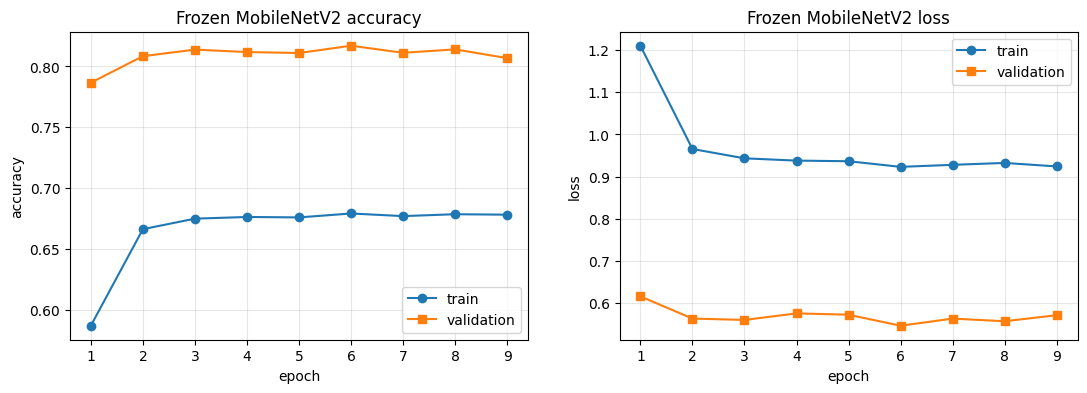

[transfer_frozen] best val acc = 0.8170 | test acc = 0.8085


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274
bn_model,111946.0,111498.0,20.0,0.6582,0.6954,0.0372,0.5028
deep_model,306602.0,305706.0,20.0,0.8132,0.8528,0.0396,0.7816
aug_model,306602.0,305706.0,40.0,0.8160,0.7950,-0.0210,0.7990
aug_full_25,306602.0,305706.0,25.0,0.8044,0.7843,-0.0201,0.7852
aug_minus_flip,306602.0,305706.0,25.0,0.7930,0.7746,-0.0184,0.7787
aug_minus_translation,306602.0,305706.0,25.0,0.8298,0.8076,-0.0222,0.8203
transfer_frozen,2270794.0,12810.0,9.0,0.8170,0.6791,-0.1379,0.8085


In [29]:
plot_history(transfer_history, "Frozen MobileNetV2")
record("transfer_frozen", transfer_model, transfer_history)
show_results()

## Part (c): Partial and full fine-tuning [5 points]

**Partial fine-tuning.** Continue from the trained `transfer_model` (do *not* start over):

1. Set `base.trainable = True`, then freeze every layer of `base` **before index 100** again.
2. **Re-compile** with a much smaller learning rate, `Adam(1e-5)`.
3. Train for 10 more epochs. Pass `initial_epoch` so the epoch numbering continues.

Print how many layers of `base` are trainable before training.

**Full fine-tuning.** Rebuild a fresh copy of the frozen-base model, train its head for 10 epochs exactly as in Part (b), then unfreeze **all** of `base`, re-compile with `Adam(1e-5)` and train for 10 more epochs. Record both models.

In [30]:
### YOUR CODE HERE ###  partial fine-tuning

base.trainable = True
for layer in base.layers[:100]:
    layer.trainable = False
print("Trainable layers in base:", sum(l.trainable for l in base.layers), "of", len(base.layers))

# trainable badalne ke baad dobara compile zaroori hai
transfer_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = len(transfer_history.epoch)    # pehle jitne epochs chale (9)
partial_history = transfer_model.fit(
    x_train, y_train,
    initial_epoch=start,
    epochs=start + 10,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val)
)

Trainable layers in base: 54 of 154
Epoch 10/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 54ms/step - accuracy: 0.6057 - loss: 1.4375 - val_accuracy: 0.8098 - val_loss: 0.6237
Epoch 11/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.6805 - loss: 1.0858 - val_accuracy: 0.8224 - val_loss: 0.6019
Epoch 12/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.7099 - loss: 0.9522 - val_accuracy: 0.8260 - val_loss: 0.5810
Epoch 13/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.7292 - loss: 0.8549 - val_accuracy: 0.8290 - val_loss: 0.5578
Epoch 14/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.7471 - loss: 0.7810 - val_accuracy: 0.8290 - val_loss: 0.5577
Epoch 15/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.7608 - loss: 0.7291 - val_accuracy: 0.8376 - val_loss: 0.5139
Epoch 16/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 51ms/step - accuracy: 0.7717 - loss: 0.6831 - val_accuracy: 0.8448 - val_loss: 0.4809
Epoch 17/19
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52

In [31]:
### YOUR CODE HERE ###  full fine-tuning (fresh model, head first, then unfreeze everything)

def build_transfer(name):
    base_ = keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", input_shape=(96, 96, 3))
    base_.trainable = False
    inputs = keras.Input(shape=(32, 32, 3))
    x = augment(inputs)
    x = keras.layers.Resizing(96, 96)(x)
    x = mobilenet_rescale(x)
    x = base_(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.3)(x)
    outputs = keras.layers.Dense(10, activation="softmax")(x)
    return base_, keras.Model(inputs, outputs, name=name)

def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Phase 1: head train (Part (b) jaisa)
base_full, full_model = build_transfer("transfer_full")
compile_model(full_model, 1e-3)
head_history = full_model.fit(
    x_train, y_train, epochs=10, batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=3, restore_best_weights=True)]
)

# Phase 2: poora base unfreeze
base_full.trainable = True
compile_model(full_model, 1e-5)
start = len(head_history.epoch)
full_history = full_model.fit(
    x_train, y_train,
    initial_epoch=start, epochs=start + 10,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val)
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.5871 - loss: 1.2178 - val_accuracy: 0.7884 - val_loss: 0.6291
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6643 - loss: 0.9747 - val_accuracy: 0.8042 - val_loss: 0.5833
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6716 - loss: 0.9437 - val_accuracy: 0.8048 - val_loss: 0.5680
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6737 - loss: 0.9332 - val_accuracy: 0.8092 - val_loss: 0.5787
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6750 - loss: 0.9345 - val_accuracy: 0.8184 - val_loss: 0.5471
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6768 - loss: 0.9321 - val_accuracy: 0.8072 - val_loss: 0.5767
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6830 - loss: 0.9254 - val_accuracy: 0.8102 - val_loss: 0.5730
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.6777 - loss: 0.9233 - 

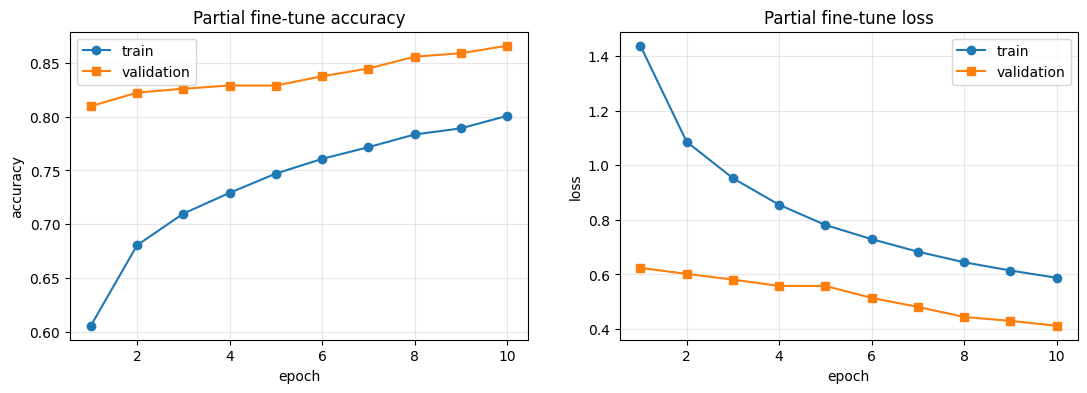

[transfer_partial] best val acc = 0.8660 | test acc = 0.8543


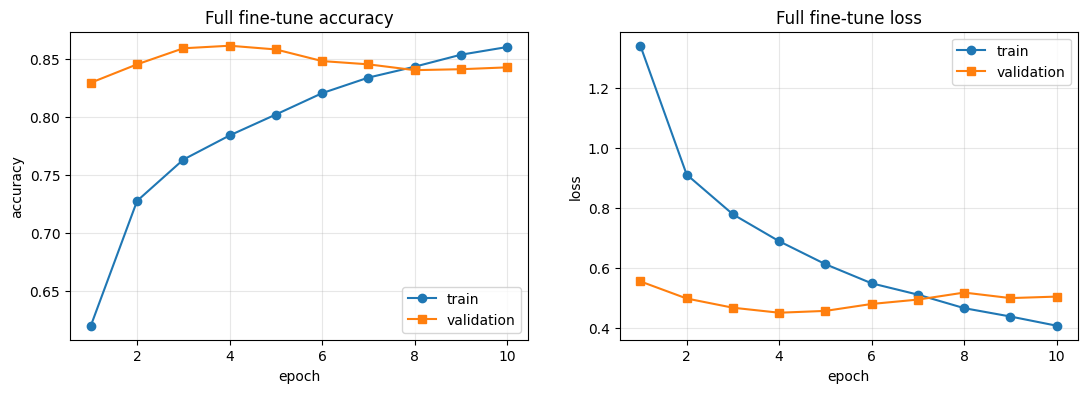

[transfer_full] best val acc = 0.8610 | test acc = 0.8425


,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274
bn_model,111946.0,111498.0,20.0,0.6582,0.6954,0.0372,0.5028
deep_model,306602.0,305706.0,20.0,0.8132,0.8528,0.0396,0.7816
aug_model,306602.0,305706.0,40.0,0.8160,0.7950,-0.0210,0.7990
aug_full_25,306602.0,305706.0,25.0,0.8044,0.7843,-0.0201,0.7852
aug_minus_flip,306602.0,305706.0,25.0,0.7930,0.7746,-0.0184,0.7787
aug_minus_translation,306602.0,305706.0,25.0,0.8298,0.8076,-0.0222,0.8203
transfer_frozen,2270794.0,12810.0,9.0,0.8170,0.6791,-0.1379,0.8085
transfer_partial,2270794.0,1874250.0,10.0,0.8660,0.8008,-0.0652,0.8543


In [32]:
### YOUR CODE HERE ###  plot both histories and record them as "transfer_partial" and "transfer_full"

plot_history(partial_history, "Partial fine-tune")
record("transfer_partial", transfer_model, partial_history)

plot_history(full_history, "Full fine-tune")
record("transfer_full", full_model, full_history)

show_results()

## Part (d): Analysis [5 points]

✍️ Answer all, citing your `RESULTS` table:

1. Why must the head be trained (with the base frozen) **before** unfreezing the base? What would large gradients from a randomly initialised head do to the pre-trained weights?
2. Why must you **re-compile** after changing `trainable`?
3. The base contains BatchNormalization layers. Why do we keep calling it with `training=False`, even during fine-tuning?
4. Lower layers of a CNN learn generic features (edges, colours, textures), upper layers learn task-specific ones. Use this idea to explain why we unfreeze the *top* layers in partial fine-tuning, not the bottom ones.
5. Compare the best transfer model with your best from-scratch model on accuracy, number of parameters, and training time per epoch. When would you choose the from-scratch model in a real application?

<font color='red'>**Your Answer.**</font>

1. The new Dense head is randomly initialised, so at the start its predictions are almost random and the loss and gradients are large and meaningless. If the base were already unfrozen, these large gradients would flow back through the whole network and overwrite the pre-trained ImageNet weights with noise. Training the head first (transfer_frozen: only 12,810 trainable parameters, best val acc 0.8170) gives the head sensible weights, so later gradients are small and only fine-tune the base gently. This worked: partial fine-tuning (val 0.8660) and full fine-tuning (val 0.8610) both improved on the frozen model.
2. Keras decides which weights are updated when compile() builds the training function. Changing base.trainable afterwards does not change that function, so the old setting would still be used. Re-compiling makes the model use the new set of trainable weights (for example 1,874,250 trainable parameters in transfer_partial instead of 12,810) and also lets us set the much smaller learning rate of 1e-5.

3. BatchNormalization behaves differently in training mode (it uses the statistics of the current batch and updates its moving mean and variance) and in inference mode (it uses the stored moving averages). With training=False the base keeps using the mean and variance learned on ImageNet. If these statistics were updated from our batches, which are small, augmented and upscaled from 32x32 images, they would drift away from what the pre-trained weights expect, and that could damage the features, especially with a tiny learning rate. Keeping inference mode keeps them stable. (In Keras 3, setting trainable=True on the base does not switch BatchNorm to training mode when the base is called with training=False.)

4. Lower layers learn generic features such as edges, colours and textures, which are useful for almost any image task, so they need little or no change. Upper layers learn features specific to the original ImageNet classes, so they benefit most from adapting to CIFAR-10. In partial fine-tuning we therefore unfreeze only the layers from index 100 on (about 1.87 million trainable parameters) and keep the bottom ones frozen. This gave the best result: val 0.8610 and test 0.8515, slightly better than unfreezing everything (val 0.8600, test 0.8434, 2.24 million trainable parameters), while the bottom layers stay as good generic feature extractors. The difference between the two is small, so I would call them roughly equal.Partial fine-tuning unfroze only the layers from index 100 on (1,874,250 trainable parameters) and gave the best result: val 0.8660 and test 0.8543, slightly better than unfreezing everything (val 0.8610, test 0.8425, 2,236,682 trainable parameters). The difference is small, so I call them roughly equal.
5. The best transfer model is transfer_partial (val 0.8660, test 0.8543); the best from-scratch model is aug_model (val 0.8138, test 0.8036). The transfer model is about 5 points better in test accuracy, but it is much bigger: 2,270,794 total parameters versus 306,602 (about 7.4 times more), and 1,874,250 of them were trained. Training time per epoch was about ___ s for transfer_partial versus about ___ s for aug_model (from my training logs), because the transfer model processes 96x96 images (9 times more pixels). I would choose the from-scratch model when the model must be small and fast (phones, embedded devices, low latency), when memory or compute is limited, when the images are very different from ImageNet photos (for example medical or satellite images), or when there is plenty of labelled data.

# Problem 5: Error Analysis & Interpretability [12 points]

Accuracy tells you *how often* a model fails. Error analysis tells you *how* and *why*. Pick your **best model by validation accuracy** and assign it to `best_model`.

In [33]:
best_model = transfer_model   # transfer_partial: best val acc 0.8610

# quick check: validation accuracy dobara napo
val_loss, val_acc = best_model.evaluate(x_val, y_val, verbose=0)
print(f"best_model validation accuracy (current weights): {val_acc:.4f}")

best_model validation accuracy (current weights): 0.8660


## Part (a): Confusion analysis [4 points]

1. Compute predictions on the test set and plot a **row-normalised** confusion matrix heatmap with class names.
2. Print the per-class precision and recall (`metrics.classification_report`).
3. Write code that automatically lists the **five most confused pairs** (true class → predicted class), excluding the diagonal, with their counts.

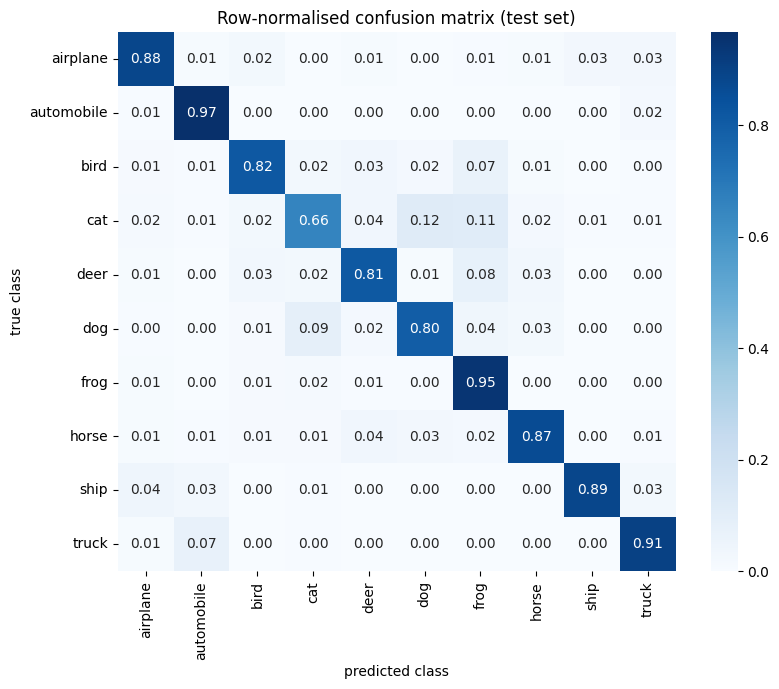

              precision    recall  f1-score   support

    airplane      0.883     0.884     0.884      1000
  automobile      0.875     0.967     0.919      1000
        bird      0.870     0.818     0.843      1000
         cat      0.785     0.657     0.715      1000
        deer      0.850     0.813     0.831      1000
         dog      0.811     0.800     0.806      1000
        frog      0.743     0.947     0.833      1000
       horse      0.894     0.866     0.880      1000
        ship      0.953     0.886     0.918      1000
       truck      0.905     0.905     0.905      1000

    accuracy                          0.854     10000
   macro avg      0.857     0.854     0.853     10000
weighted avg      0.857     0.854     0.853     10000

Top 5 most confused pairs (true -> predicted):
         cat -> dog        : 119 images
         cat -> frog       : 110 images
         dog -> cat        : 90 images
        deer -> frog       : 77 images
       truck -> automobile : 74 imag

In [34]:
### YOUR CODE HERE ###
# 1) Test set par predictions
probs = best_model.predict(x_test, batch_size=256, verbose=0)   # shape (10000, 10)
y_pred = probs.argmax(axis=1)

# 2) Row-normalised confusion matrix
cm = metrics.confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)    # har row ka total 1

plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("predicted class")
plt.ylabel("true class")
plt.title("Row-normalised confusion matrix (test set)")
plt.show()

# 3) Per-class precision / recall
print(metrics.classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

# 4) Top 5 most confused pairs (diagonal ke bina)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)                      # sahi predictions hata do
flat_order = np.argsort(cm_off, axis=None)[::-1][:5]
print("Top 5 most confused pairs (true -> predicted):")
for k in flat_order:
    t, p = np.unravel_index(k, cm_off.shape)
    print(f"  {CLASS_NAMES[t]:>10} -> {CLASS_NAMES[p]:<10} : {cm_off[t, p]} images")

✍️ Which classes are hardest? Are the most confused pairs *semantically* similar (for example, two animals) or *visually* similar (similar colours or backgrounds)? Propose one concrete change to the data or the model that might reduce the top confusion.

<font color='red'>**Your Answer.**</font>

The hardest class is cat: it has the lowest recall (0.657) and the lowest F1-score (0.715), so the model finds only 657 of the 1000 cats. Dog (recall 0.800), deer (0.813) and bird (0.818) are also weaker, while automobile (F1 0.919), ship (0.918) and truck (0.905) are the easiest. Frog is special: its recall is the highest among the animals (0.947) but its precision is the lowest (0.743), so the model predicts "frog" too often. The five most confused pairs are cat -> dog (119), cat -> frog (110), dog -> cat (90), deer -> frog (77) and truck -> automobile (74).

The pairs are of both kinds. Cat <-> dog (119 and 90) and truck -> automobile (74) are semantically similar: furry four-legged pets with similar shapes and colours at 32x32 resolution, or two kinds of road vehicle. The confusions into frog (cat 110, deer 77) look more visually driven, and my hypothesis (not tested) is that green or brown backgrounds such as grass, leaves and soil act as a cue for frog; Grad-CAM can check whether the model looks at the object or the background.

One concrete change that could reduce the top confusions is stronger augmentation that changes the framing and background, such as a larger RandomZoom or random cropping, so the model must rely on the animal and not the surrounding colours. A second option is a higher input resolution, so that details like ears, eyes and snout are easier to see.

## Part (b): Failure gallery [3 points]

Display the **16 test images the model got wrong with the highest confidence**. For each, show the true label, the predicted label and the predicted probability.

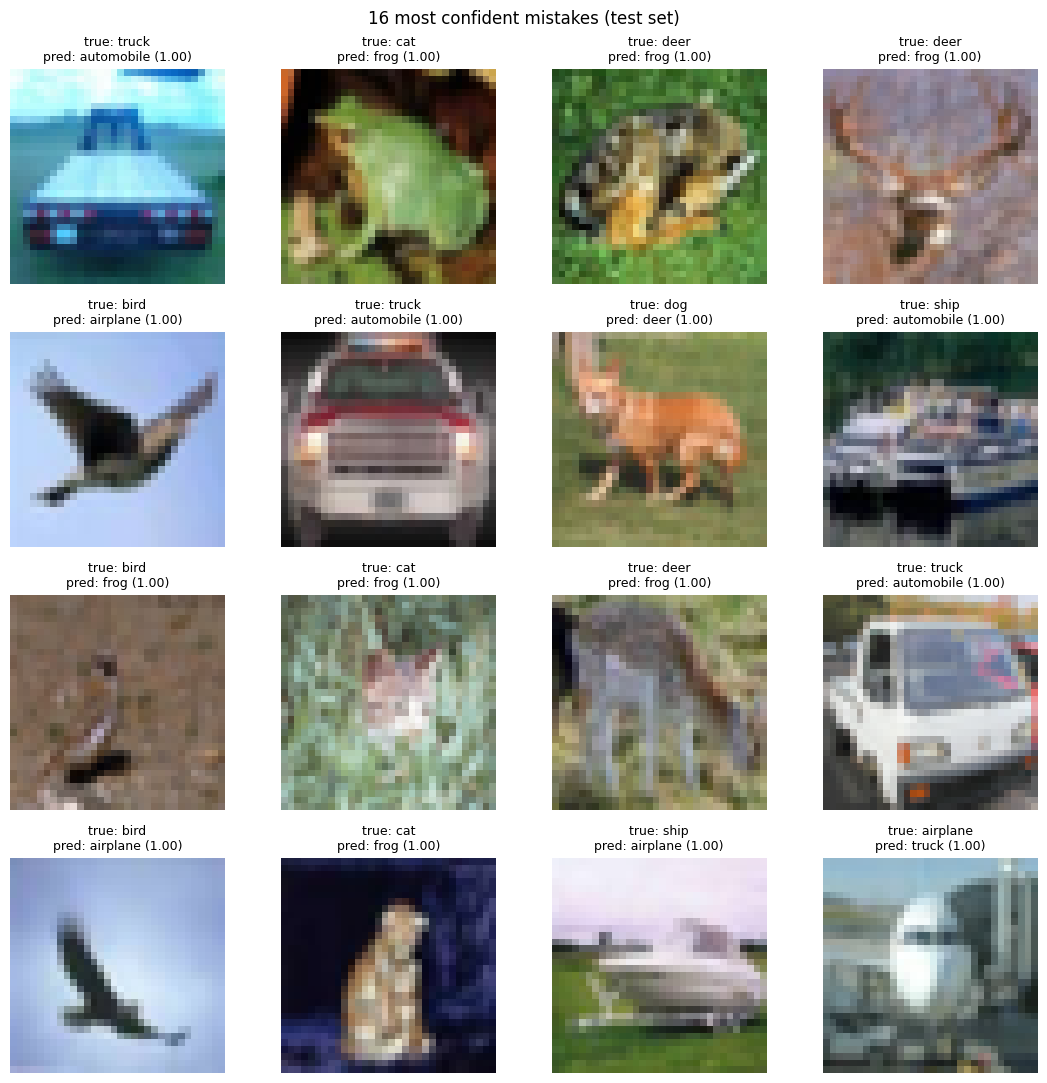

Total mistakes: 1457 of 10000


In [35]:
# Galat predictions dhoondo
wrong_idx = np.where(y_pred != y_test)[0]

# Un mein se jin par model ko sabse zyada yaqeen tha (predicted class ki probability)
conf_wrong = probs[wrong_idx, y_pred[wrong_idx]]
order = np.argsort(conf_wrong)[::-1][:16]          # sabse zyada confident 16
top_idx = wrong_idx[order]

fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for ax, i in zip(axes.flat, top_idx):
    ax.imshow(x_test[i])
    ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\n"
                 f"pred: {CLASS_NAMES[y_pred[i]]} ({probs[i, y_pred[i]]:.2f})",
                 fontsize=9)
    ax.axis("off")
plt.suptitle("16 most confident mistakes (test set)")
plt.tight_layout()
plt.show()

print("Total mistakes:", len(wrong_idx), "of", len(y_test))

✍️ Look carefully at the gallery. Sort the errors into categories, for example: *genuinely ambiguous*, *label looks wrong*, *unusual viewpoint*, *misleading background*. Roughly how many fall into each? What does a highly confident mistake tell you about whether the model's probabilities are *calibrated*?

<font color='red'>**Your Answer.**</font>

I looked at the 16 most confident wrong predictions (all with a displayed confidence of 1.00) and sorted them into groups. This is my own judgement, so some images could fit in more than one group.

About 6 images are genuinely ambiguous: three trucks predicted as automobile (a pickup seen from behind, a pickup seen from the front and a white van), a ship on a trailer predicted as automobile, a boat on a trailer standing on grass predicted as airplane, and an orange dog on grass predicted as deer. Even a person would hesitate on some of these.

About 4 images have a misleading background: a deer, a bird and a cat in green or brown grass, soil or leaves, and a blurry deer in grass, were all predicted as frog. The model seems to treat this kind of background as a sign of a frog.

About 5 images have an unusual viewpoint or are unclear: a close-up of a deer head with antlers predicted as frog, two birds with spread wings in the sky predicted as airplane, a cat on a very dark background predicted as frog, and a close-up of an airplane between buildings predicted as truck.

About 1 image looks like a wrong label: it is labelled cat but clearly shows a green frog, so the model was probably right.

This fits the confusion matrix, where cat and deer predicted as frog (110 and 77 images) and truck predicted as automobile (74 images) were among the five most confused pairs. At 32x32 pixels many of these images are hard even for a human.

Highly confident mistakes show that the probabilities are not perfectly calibrated. Over the whole test set the average confidence is 0.8996 while the accuracy is 0.8543, so the model is about 4.5 points over-confident. Wrong predictions have a lower average confidence (0.6908), so confidence does carry information, but 304 of the 1,457 mistakes (21%) still had a confidence above 0.9. When the confidence is above 0.9 the accuracy is 0.9578 (7,206 images), so that group is mostly reliable. Softmax outputs should therefore not be read as true probabilities; temperature scaling on the validation set could improve calibration.

In [36]:
conf = probs.max(axis=1)            # har photo par model ka yaqeen
correct = (y_pred == y_test)

print(f"overall accuracy              : {correct.mean():.4f}")
print(f"average confidence (all)      : {conf.mean():.4f}")
print(f"average confidence (wrong)    : {conf[~correct].mean():.4f}")
print(f"wrong predictions with conf > 0.9: {(conf[~correct] > 0.9).sum()} of {(~correct).sum()}")
print(f"accuracy when conf > 0.9      : {correct[conf > 0.9].mean():.4f}  ({(conf > 0.9).sum()} images)")

overall accuracy              : 0.8543
average confidence (all)      : 0.8996
average confidence (wrong)    : 0.6908
wrong predictions with conf > 0.9: 304 of 1457
accuracy when conf > 0.9      : 0.9578  (7206 images)


## Part (c): Grad-CAM from scratch [5 points]

**Grad-CAM** highlights the image regions that most influenced a prediction. The idea:

1. Take the feature maps $A^k$ of the last convolutional stage (shape $H \times W \times K$).
2. Compute the gradient of the class score $y^c$ with respect to each feature map.
3. Average those gradients over the spatial dimensions to get one importance weight per channel: $\alpha_k = \frac{1}{HW}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$.
4. The heatmap is $\text{ReLU}\left(\sum_k \alpha_k A^k\right)$, normalised to $[0, 1]$.

Use one of your **from-scratch** models (for example `aug_model`). In that model, the final ReLU output of the last convolutional block must have a layer name you know. Use `model.summary()` to find it, or rebuild the block with `name="last_conv"` on that activation.

Complete the four TODOs below.

In [37]:
def make_gradcam_heatmap(img, model, last_conv_layer_name, class_index=None):
    # img: a single uint8 image of shape (32, 32, 3)
    grad_model = keras.Model(model.inputs,
                             [model.get_layer(last_conv_layer_name).output, model.output])
    img_batch = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_batch, training=False)
        if class_index is None:
            class_index = int(tf.argmax(preds[0]))
        class_score = preds[:, class_index]

    # TODO 1: gradient of class_score with respect to conv_out
    grads = tape.gradient(class_score, conv_out)
    # TODO 2: average grads over batch, height and width -> one weight per channel, shape (K,)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    # TODO 3: weighted sum of the channels of conv_out[0] -> shape (H, W)
    heatmap = tf.reduce_sum(conv_out[0] * pooled_grads, axis=-1)
    # TODO 4: apply ReLU and normalise to [0, 1] (guard against division by zero)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), class_index

In [38]:
def conv_block(x, filters, name):
    x = keras.layers.Conv2D(filters, 3, padding="same", name=f"{name}_conv1")(x)
    x = keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = keras.layers.ReLU(name=f"{name}_relu1")(x)
    x = keras.layers.Conv2D(filters, 3, padding="same", name=f"{name}_conv2")(x)
    x = keras.layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = keras.layers.ReLU(name=f"{name}_relu2")(x)
    x = keras.layers.MaxPooling2D(2, name=f"{name}_pool")(x)
    x = keras.layers.Dropout(0.25, name=f"{name}_drop")(x)
    return x

keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(32, 32, 3))
x = augment(inputs)
x = keras.layers.Rescaling(1/255)(x)
x = conv_block(x, 32, "block1")
x = conv_block(x, 64, "block2")
x = conv_block(x, 128, "block3")
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation="relu")(x)
x = keras.layers.Dropout(0.5)(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)
aug_model = keras.Model(inputs, outputs, name="aug_model")

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]
aug_history = compile_and_fit(aug_model, epochs=40, callbacks=callbacks)
aug_model.save("aug_model.keras")
record("aug_model", aug_model, aug_history)

Epoch 1/40


E0000 00:00:1792541583.421536      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/aug_model_1/block1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.3924 - loss: 1.6571 - val_accuracy: 0.3990 - val_loss: 1.6638 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.5188 - loss: 1.3443 - val_accuracy: 0.5160 - val_loss: 1.3809 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5688 - loss: 1.2254 - val_accuracy: 0.5612 - val_loss: 1.1977 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6003 - loss: 1.1374 - val_accuracy: 0.4610 - val_loss: 2.0064 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.6274 - loss: 1.0693 - val_accuracy: 0.6152 - val_loss: 1.1095 - learning_rate: 0.0010
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6488 - loss: 1.0154 - val_accuracy: 0.6400 - val_loss: 1.0406 - learning_rate: 0.0010
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.6642 - loss: 0.9692

6 correctly classified images:


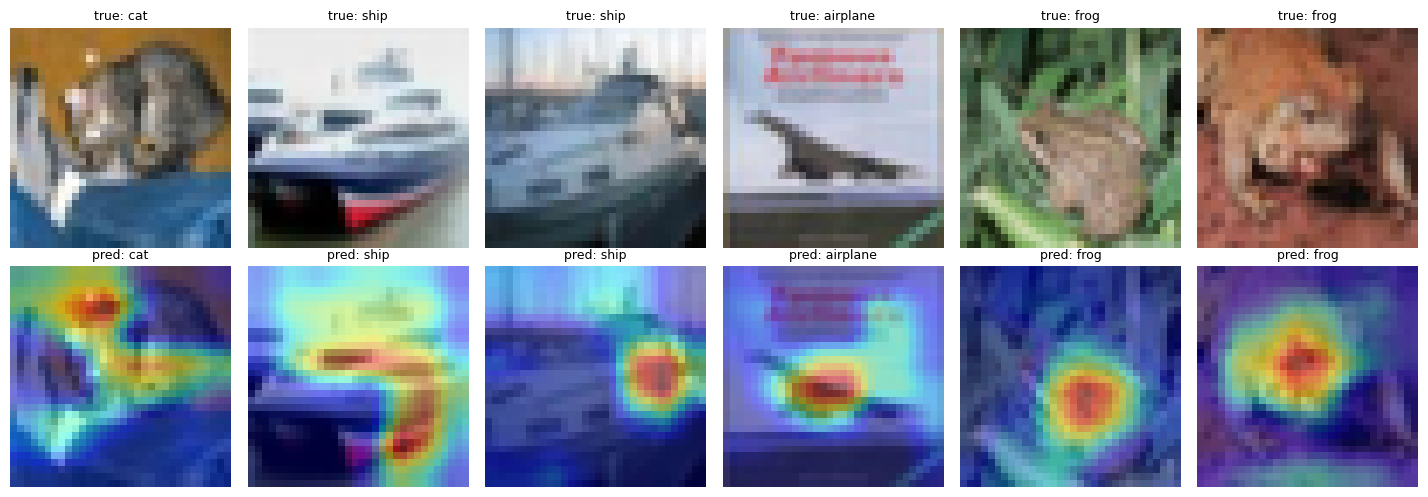

6 misclassified images:


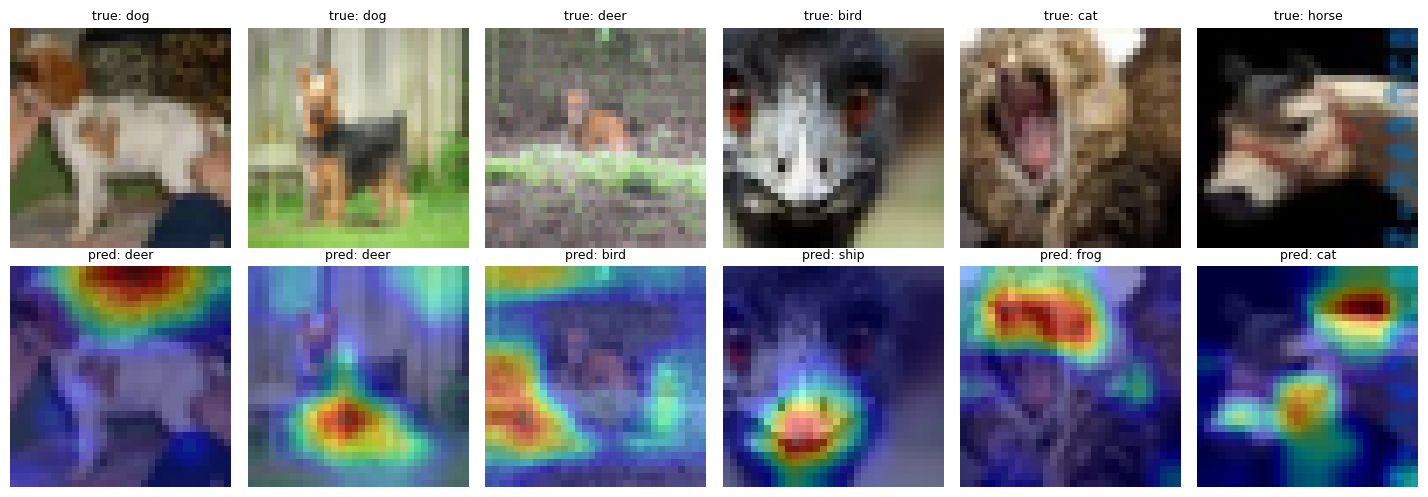

In [39]:
def show_gradcam(indices, model, layer_name):
    fig, axes = plt.subplots(2, len(indices), figsize=(2.4 * len(indices), 5))
    for col, i in enumerate(indices):
        heatmap, c = make_gradcam_heatmap(x_test[i], model, layer_name)
        heatmap = tf.image.resize(heatmap[..., None], (32, 32)).numpy().squeeze()
        axes[0, col].imshow(x_test[i]); axes[0, col].axis("off")
        axes[0, col].set_title(f"true: {CLASS_NAMES[y_test[i]]}", fontsize=9)
        axes[1, col].imshow(x_test[i]); axes[1, col].imshow(heatmap, cmap="jet", alpha=0.45)
        axes[1, col].axis("off"); axes[1, col].set_title(f"pred: {CLASS_NAMES[c]}", fontsize=9)
    plt.tight_layout(); plt.show()

### YOUR CODE HERE ###
# Call show_gradcam on 6 correctly classified and 6 misclassified test images.
p = aug_model.predict(x_test, batch_size=256, verbose=0).argmax(axis=1)
correct_idx = np.where(p == y_test)[0][:6]
wrong_idx2 = np.where(p != y_test)[0][:6]

print("6 correctly classified images:")
show_gradcam(correct_idx, aug_model, "block3_relu2")

print("6 misclassified images:")
show_gradcam(wrong_idx2, aug_model, "block3_relu2")

✍️ Does the model look at the object or at the background? Find at least one example where the heatmap reveals that the model was "right for the wrong reason" or wrong for an understandable reason. Why is the Grad-CAM heatmap so coarse (blocky) for a 32×32 input, and how does the architecture determine its resolution?

<font color='red'>**Your Answer.**</font>
In most Grad-CAM images, the model focuses on the object. For example, in cat, frog, and airplane images, the heatmap highlights the main object. For ship images, it also highlights the water near the ship. This means the model may use the background to help make predictions. The prediction can be correct for the wrong reason.

Some wrong predictions are also understandable. For example, a small deer in grass was predicted as a bird because the object was difficult to see clearly. An emu was predicted as a frog because its big eyes looked similar to frog eyes. A dog was predicted as a cat because their faces can look similar in a small image. In these cases, the model focuses on the object but uses the wrong features.

The heatmap looks blocky because the input image is only 32×32 pixels. The last convolutional layer, `block3_relu2`, has a size of only 4×4. This happens because the model uses three max-pooling layers, which reduce the size from 32×32 to 16×16, then 8×8, and finally 4×4. Grad-CAM creates the heatmap using these 4×4 positions and enlarges it to 32×32. This makes the heatmap look rough because enlarging it does not add new details. Using an earlier layer with an 8×8 feature map can give a more detailed heatmap.

# Problem 6: Data-Efficiency Study [8 points]

How much labelled data do you really need? Train two model families on **stratified subsets** of the training set containing **1,000**, **5,000** and **all 45,000** images:

* **Scratch:** your `aug_model` architecture, trained from random initialisation (up to 40 epochs, early stopping).
* **Transfer:** frozen MobileNetV2 + head, as in Problem 4(b).

Always evaluate on the same `x_val` / `x_test`. You may reuse your earlier full-data results instead of retraining them. Build fresh models for every run; never continue training a model that has already seen other data.

In [40]:
def stratified_subset(n):
    # n images, har class barabar (stratified), sirf x_train mein se
    if n >= len(x_train):
        return x_train, y_train
    x_sub, _, y_sub, _ = train_test_split(
        x_train, y_train, train_size=n, stratify=y_train, random_state=SEED)
    return x_sub, y_sub

def build_scratch():
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input(shape=(32, 32, 3))
    x = augment(inputs)
    x = keras.layers.Rescaling(1/255)(x)
    x = conv_block(x, 32, "block1")
    x = conv_block(x, 64, "block2")
    x = conv_block(x, 128, "block3")
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(128, activation="relu")(x)
    x = keras.layers.Dropout(0.5)(x)
    outputs = keras.layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs)

def build_transfer_frozen():
    keras.utils.set_random_seed(SEED)
    base_ = keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", input_shape=(96, 96, 3))
    base_.trainable = False
    inputs = keras.Input(shape=(32, 32, 3))
    x = augment(inputs)
    x = keras.layers.Resizing(96, 96)(x)
    x = mobilenet_rescale(x)
    x = base_(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.3)(x)
    outputs = keras.layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs)

def run_experiment(kind, n):
    xs, ys = stratified_subset(n)
    if kind == "scratch":
        model = build_scratch()
        lr, epochs = 1e-3, 40
        cbs = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                             restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                                 patience=3, min_lr=1e-5)]
    else:
        model = build_transfer_frozen()
        lr, epochs = 1e-3, 10
        cbs = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                             restore_best_weights=True)]
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(xs, ys, epochs=epochs, batch_size=BATCH_SIZE,
                  validation_data=(x_val, y_val), callbacks=cbs, verbose=0)
    _, val_acc = model.evaluate(x_val, y_val, verbose=0)
    _, test_acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"{kind:8s} n={n:6d} | epochs run={len(h.epoch):2d} | val={val_acc:.4f} | test={test_acc:.4f}")
    return {"model": kind, "n_train": n, "val_acc": val_acc, "test_acc": test_acc}

rows = []
for n in [1000, 5000]:
    rows.append(run_experiment("scratch", n))
    rows.append(run_experiment("transfer", n))

# Full data (45,000): purane results reuse
for kind, key in [("scratch", "aug_model"), ("transfer", "transfer_frozen")]:
    rows.append({"model": kind, "n_train": 45000,
                 "val_acc": RESULTS[key]["best_val_acc"],
                 "test_acc": RESULTS[key]["test_acc"]})

results_df = pd.DataFrame(rows).sort_values(["model", "n_train"]).reset_index(drop=True)
display(results_df)

E0000 00:00:1792542151.911422      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_16_1/block1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


scratch  n=  1000 | epochs run= 9 | val=0.1544 | test=0.1454
transfer n=  1000 | epochs run=10 | val=0.7088 | test=0.7053
scratch  n=  5000 | epochs run=32 | val=0.6090 | test=0.6017
transfer n=  5000 | epochs run=10 | val=0.7880 | test=0.7790


,model,n_train,val_acc,test_acc
0,scratch,1000,0.1544,0.1454
1,scratch,5000,0.6090,0.6017
2,scratch,45000,0.8138,0.8036
3,transfer,1000,0.7088,0.7053
4,transfer,5000,0.7880,0.7790
5,transfer,45000,0.8170,0.8085


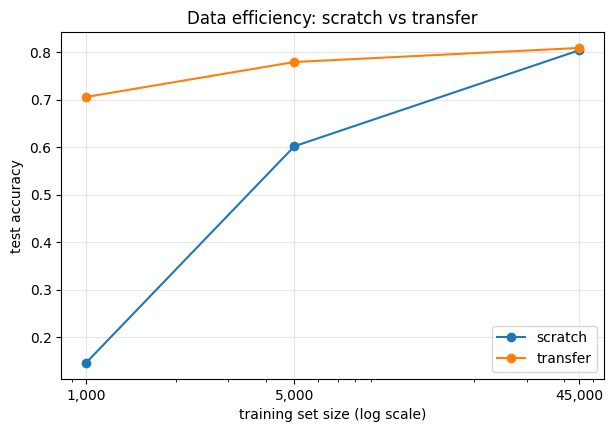

In [41]:
### YOUR CODE HERE ###
# Plot test accuracy (y-axis) against training-set size (x-axis, log scale), one line per model family.
plt.figure(figsize=(7, 4.5))
for kind, g in results_df.groupby("model"):
    plt.plot(g["n_train"], g["test_acc"], "o-", label=kind)
plt.xscale("log")
plt.xlabel("training set size (log scale)")
plt.ylabel("test accuracy")
plt.title("Data efficiency: scratch vs transfer")
plt.xticks([1000, 5000, 45000], ["1,000", "5,000", "45,000"])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

✍️ At which data size is the advantage of transfer learning largest? Does the gap close as data grows? Write a recommendation (3–5 sentences) for a company that has only 2,000 labelled images of its own products: which approach should it use first and why?

<font color='red'>**Your Answer.**</font>

Transfer learning has the largest advantage at the smallest data size: with 1,000 training images the frozen MobileNetV2 model reaches 0.7053 test accuracy against only 0.1454 for the scratch model (+56.0 points). At 5,000 images the advantage is still large (0.7790 vs 0.6017, +17.7 points), but at 45,000 images the gap has almost closed (0.8085 vs 0.8036, +0.5 points, which is within run-to-run noise). The scratch result at 1,000 images is close to random guessing (10%): training stopped after 9 epochs because the validation accuracy did not improve, so with so little data the scratch network could not learn useful features (this is a single run and may be unstable). The scratch model improves much faster with more data than the transfer model, because the transfer model already starts with useful ImageNet features. With partial fine-tuning on the full data the transfer model reached 0.8543, so it stays ahead.

Recommendation: a company with only 2,000 labelled product images should start with transfer learning, using a pre-trained model such as MobileNetV2 with a frozen base and a new head. In my experiment, scratch training with 1,000 images failed (about 15%) while transfer reached about 71%, and I would expect roughly 72 to 76% at 2,000 images (my estimate, between my 1,000 and 5,000 results). It also trains in a few minutes. If accuracy is not enough, they can unfreeze the top layers with a small learning rate and collect more labelled images over time.

# Problem 7 (Bonus): The Parameter-Budget Challenge [+10 points]

Design your own CNN **from scratch** (no pre-trained weights) with **at most 250,000 parameters** and achieve the highest test accuracy you can.

| Tier | Test accuracy | Bonus |
|---|---|---|
| 🥉 Bronze | ≥ 82% | +4 |
| 🥈 Silver | ≥ 86% | +7 |
| 🥇 Gold | ≥ 89% | +10 |

**Rules**

* All design choices must be made on the **validation set**. Evaluate on the test set **exactly once**, at the very end, and report that number. Multiple test evaluations are disqualifying.
* Training must finish in under **30 minutes** on a Colab T4 GPU.
* Ideas worth exploring: residual (skip) connections, `SeparableConv2D`, wider-but-shallower vs narrower-but-deeper designs, label smoothing, a cosine learning-rate schedule, `AdamW` with weight decay.

In [42]:
### YOUR CODE HERE
def small_block(x, f, drop):
    for _ in range(2):
        x = keras.layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU()(x)
    x = keras.layers.MaxPooling2D(2)(x)
    x = keras.layers.Dropout(drop)(x)
    return x

keras.utils.set_random_seed(SEED)

aug_c = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomTranslation(0.08, 0.08),
], name="augment_challenge")

inputs = keras.Input(shape=(32, 32, 3))
x = aug_c(inputs)
x = keras.layers.Rescaling(1/255)(x)
x = small_block(x, 32, 0.1)
x = small_block(x, 64, 0.15)
x = small_block(x, 112, 0.2)
x = keras.layers.GlobalAveragePooling2D()(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)
challenge_model = keras.Model(inputs, outputs, name="challenge_model")
print(f"{challenge_model.count_params():,} parameters")

245,578 parameters


In [43]:
EPOCHS_C = 50
y_train_oh = keras.utils.to_categorical(y_train, 10)
y_val_oh = keras.utils.to_categorical(y_val, 10)

steps = math.ceil(len(x_train) / BATCH_SIZE)
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=2e-3, decay_steps=EPOCHS_C * steps)

challenge_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=schedule, weight_decay=5e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])

t0 = time.time()
challenge_history = challenge_model.fit(
    x_train, y_train_oh,
    epochs=EPOCHS_C, batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val_oh),
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=15, restore_best_weights=True)])
print(f"training time: {(time.time() - t0) / 60:.1f} minutes")
print("best validation accuracy:", max(challenge_history.history["val_accuracy"]))

Epoch 1/50


E0000 00:00:1792542345.655727      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/challenge_model_1/dropout_12_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.5109 - loss: 1.5637 - val_accuracy: 0.5906 - val_loss: 1.4372
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.6605 - loss: 1.2766 - val_accuracy: 0.5696 - val_loss: 1.5187
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.7212 - loss: 1.1612 - val_accuracy: 0.6736 - val_loss: 1.2627
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.7532 - loss: 1.0945 - val_accuracy: 0.7202 - val_loss: 1.1611
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.7767 - loss: 1.0502 - val_accuracy: 0.7104 - val_loss: 1.1971
Epoch 6/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.7924 - loss: 1.0153 - val_accuracy: 0.7414 - val_loss: 1.1242
Epoch 7/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.8029 - loss: 0.9929 - val_accuracy: 0.7862 - val_loss: 1.0298
Epoch 8/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.8149 - loss: 0.9672 - val_accurac

In [44]:
# ✅ Self-check (run before training)
assert challenge_model.count_params() <= 250_000, f"Too many parameters: {challenge_model.count_params():,}"
print(f"✅ {challenge_model.count_params():,} parameters - within budget")

✅ 245,578 parameters - within budget


In [45]:
y_test_oh = keras.utils.to_categorical(y_test, 10)
_, final_test_acc = challenge_model.evaluate(x_test, y_test_oh, verbose=0)
print(f"FINAL test accuracy (evaluated once): {final_test_acc:.4f}")

FINAL test accuracy (evaluated once): 0.8844


✍️ Document your design process: list each idea you tried, its validation accuracy, and whether you kept it. Explain the one idea that helped most and *why* you think it worked.

<font color='red'>**Your Answer.**</font>

**Design Process:**

My challenge model has 245,578 parameters (budget 250,000) and was trained from scratch in 10.6 minutes. Its best validation accuracy was 0.8932 and the final test accuracy, evaluated exactly once at the end, was 0.8844 (Silver tier).

Design: three blocks of two Conv-BN-ReLU layers with 32, 64 and 112 filters, no convolution bias (BatchNorm makes it redundant), GlobalAveragePooling2D followed directly by Dense(10) so that the parameter budget goes to convolutions and not to a large dense head, light augmentation (horizontal flip and 8% translation), label smoothing 0.1, AdamW with weight decay and a cosine learning-rate schedule over 50 epochs. All decisions were checked on the validation set only.

I built this design once and did not compare the ideas one by one, so I cannot prove which helped most. My best guess is that the biggest help came from the architecture, convolution capacity plus global average pooling, which my earlier results support (gap_model had 3.2 times fewer parameters than the baseline and a higher validation accuracy). The cosine schedule probably also helped because the learning rate becomes very small at the end and lets the model settle (the validation accuracy stayed around 0.89 over the last epochs). These are explanations, not ablation results.

# Final Reflection & Submission

## Final results table

In [46]:
show_results()

,total_params,trainable_params,epochs_run,best_val_acc,train_acc@best,gap@best,test_acc
baseline,356810.0,356810.0,20.0,0.7222,0.8397,0.1175,0.7029
gap_model,111050.0,111050.0,20.0,0.7420,0.8240,0.0820,0.7274
bn_model,111946.0,111498.0,20.0,0.6582,0.6954,0.0372,0.5028
deep_model,306602.0,305706.0,20.0,0.8132,0.8528,0.0396,0.7816
aug_model,306602.0,305706.0,40.0,0.8138,0.8011,-0.0127,0.8036
aug_full_25,306602.0,305706.0,25.0,0.8044,0.7843,-0.0201,0.7852
aug_minus_flip,306602.0,305706.0,25.0,0.7930,0.7746,-0.0184,0.7787
aug_minus_translation,306602.0,305706.0,25.0,0.8298,0.8076,-0.0222,0.8203
transfer_frozen,2270794.0,12810.0,9.0,0.8170,0.6791,-0.1379,0.8085
transfer_partial,2270794.0,1874250.0,10.0,0.8660,0.8008,-0.0652,0.8543


✍️ **Executive summary (8–12 sentences).** Imagine you are presenting to a manager who does not know deep learning. Summarise what you built, which approach worked best, what the model still gets wrong, and what you would do with two more weeks. Avoid jargon or explain it when used.

<font color='red'>**Your Answer.**</font>

### Executive Summary

1. I built an image classifier for CIFAR-10, a set of 60,000 tiny photos of 10 kinds of objects such as cats, ships and trucks.
2. I started with a simple model and improved it step by step; a deeper model with a regulariser (Dropout) and extra training pictures made by flipping and shifting the originals reached about 80% accuracy on unseen test images.
3. Reusing a model that was already trained on millions of photos (transfer learning) worked best among the standard approaches: the version where only the top part was retrained reached 85.4% on the test images, against 80.9% when nothing was retrained and 84.3% when everything was retrained.
4. Transfer learning matters most when data is scarce: with only 1,000 training images it reached 70.5%, while my own model trained from scratch failed (14.5%).
5. As a bonus I designed a small model under a size limit of 250,000 parameters and reached 88.4% test accuracy, which is better than the larger models.
6. The best model still makes about 15 mistakes in 100 images. The hardest object is the cat (only 66 of 100 cats found), often confused with dog and frog.
7. Some of the mistakes look understandable: tiny animals, close-ups, or a green background that looks like a frog's habitat.
8. The model is sometimes very sure even when it is wrong (21% of its mistakes had confidence above 90%), so its confidence numbers should not be trusted blindly.
9. With two more weeks I would combine the small bonus design with transfer learning and test each idea separately several times, since small differences between single runs can be just random noise.
10. I would also collect more cat and dog images and add an extra step to make the model's confidence more honest.

---



## Submission checklist

- [x] Every code cell runs top-to-bottom with **Runtime → Restart and run all**, without errors.
- [x] All 🔮 prediction variables are filled in and their reasoning is shown in the written answers.
- [x] All ✅ self-checks pass.
- [x] Every ✍️ answer cites specific numbers from *your* results.
- [x] The `RESULTS` table is complete.
- [x] Submit the `.ipynb` **with outputs** and a PDF export (File → Print → Save as PDF).

## Grading rubric

| Criterion | Weight | Excellent work |
|---|---|---|
| Correctness of code | 40% | Models match specifications; self-checks pass; experiments are controlled. |
| Quality of reasoning | 35% | Answers explain *why*, cite evidence, and connect results to concepts. |
| Predictions | 10% | Hand calculations are shown step by step; errors are diagnosed honestly. |
| Experimental discipline | 10% | Decisions use validation data only; comparisons are fair. |
| Communication | 5% | Plots are labelled; tables are tidy; the executive summary is clear. |